# Recurrent neural networks: the complete lecture, in TensorFlow/Keras and PyTorch

**FYS-STK3155/4155, fall 2026**

This notebook contains the code behind every figure and number in the slides
`week45rnn.pdf` — the stand-alone lecture on recurrent networks that merges
the week-45 lecture, the material on recurrent dynamics and backpropagation
through time of the FYS5429 notes (now Sections 11.3.1, 11.4.1–11.4.7, 11.5.1,
11.5.4 and 11.6.2 of Chapter 11) and the gated cells. Every recurrent network
in it is a library layer — `tf.keras.layers.SimpleRNN` / `LSTM` / `GRU` or
`torch.nn.RNN` / `LSTM` / `GRU` — and every gradient is computed by the
libraries' automatic differentiation. The theory of Chapter 11 (the recursion
of backpropagation through time, the product of Jacobians of Theorem 11.1,
the LSTM cell path of Eq. (11.53)) is *measured* on those layers with
`torch.autograd` rather than re-implemented. NumPy is used only for data.

*Part 1* is where the recurrence comes from (Sections 11.3 and 11.3.1):
Newton's equation for a damped oscillator reduced to two first-order
equations and discretised by forward Euler; the state-space form
$\boldsymbol{s}_{i+1} = \boldsymbol{A}\boldsymbol{s}_i + \boldsymbol{B}F_i$,
Eq. (11.15), which is a linear recurrent network, Eq. (11.17); the Euler
eigenvalues and why RK4 generates the data; the eigenmode numbers and the
transient growth of a non-normal matrix, Eq. (11.43).

*Part 2* is the RNN as a discrete-time dynamical system (Section 11.2.1).

*Part 3* is the layers themselves (Section 11.8) — parameter counts, the same
weights in both libraries, `loss.backward()` as a linear map of the output
error — and the worked two-step example of Section 11.4.5, by hand and with
`torch.autograd`.

*Part 4* is why long sequences are hard (Sections 11.5 and 11.7.1): the
Jacobian $\partial\boldsymbol{h}^{(T)}/\partial\boldsymbol{h}^{(t)}$ of
Theorem 11.1 from `torch.autograd` on `nn.RNN`, the memory horizon of
Corollary 11.2, and the LSTM cell path for three forget-gate biases.

*Part 5* is the oscillator experiment (Section 11.6.1) in Keras and in
PyTorch, and the free rollout of Section 11.6.2: the same network fed its own
predictions.

*Part 6* is four applications: the sine-wave forecast, MNIST read row by
row with the simple RNN and the LSTM, spoken digits from the Free Spoken
Digit Dataset, and the adding problem with the simple RNN, the LSTM and the
GRU.

The functions are the ones in `make_week45rnn_figures.py`. Parts 1–4 run in
about a minute, Part 5 in three to four minutes, and Part 6 in twenty to
forty minutes on a laptop CPU. PyTorch and TensorFlow are needed throughout
(`pip install torch tensorflow`). The MNIST data are read from `mnist.npz`
and the spoken digits from `fsdd_features.npz` in this folder (if the
latter is absent the wav files are fetched from GitHub and the features
computed).

In [1]:
import glob
import os
import subprocess
import time
import wave
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")
import torch
# torch and tensorflow ship different LLVM runtimes; torch loads part of its
# optimiser machinery lazily at the first optimizer.step(), which crashes if
# tensorflow was imported in between.  So: torch first, one dummy step, then tf.
_p = torch.nn.Parameter(torch.zeros(1))
_p.grad = torch.zeros(1)
torch.optim.Adam([_p]).step()
import tensorflow as tf

BLUE, RED, YELLOW, GREY, GREEN = "#004488", "#BB5566", "#DDAA33", "#777777", "#228833"
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "legend.fontsize": 8.5,
                     "figure.dpi": 110})
HERE = os.getcwd()


def savefig(fig, name):
    fig.savefig(os.path.join(HERE, name + ".png"), bbox_inches="tight", dpi=150)
    plt.show()

I0000 00:00:1794081865.242225    8024 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794081866.371638    8024 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Part 1: where the recurrence comes from — a differential equation (Section 11.3)

Almost everything in the course so far has assumed independent and
identically distributed samples and a fixed input dimension. A sequence
breaks both: the value of a detector trace at one sample is strongly
informative about the next (that *is* the signal), and sequences come in
different lengths. A recurrent network processes one element at a time and
carries a **state** forward, Eq. (11.3),

$$\boldsymbol{h}_t = f_\theta(\boldsymbol{h}_{t-1}, \boldsymbol{x}_t), \qquad
\hat{\boldsymbol{y}}_t = g_\theta(\boldsymbol{h}_t),$$

which is exactly the structure of a Markovian dynamical system with a learned
update map. The recurrence is not arbitrary. Take Newton's equation for a
damped harmonic oscillator in dimensionless time, Eq. (11.8),

$$\frac{d^2x}{dt^2} + \eta\frac{dx}{dt} + x(t) = F(t),$$

rewrite it as two first-order equations, Eq. (11.9), $v = dx/dt$ and
$dv/dt = F - \eta v - x$, and discretise the velocity equation by forward
Euler, Eq. (11.10),

$$v_{i+1} = v_i + \Delta t\,(F_i - \eta v_i - x_i) =: h_i(x_i, v_i, F_i).$$

The right-hand side is a function of the current state and the current
input; but $v_i$ was produced by the same rule one step earlier, so
$v_{i+1} = h_i(x_i, h_{i-1}, F_i)$, Eq. (11.12), which after renaming is
Eq. (11.13), $\boldsymbol{h}_i = h(\boldsymbol{x}_i, \boldsymbol{h}_{i-1})$.
The hidden state plays the role of the integrator's internal state,
$\boldsymbol{W}$ plays the role of $1 - \eta\Delta t$, and the training data
supply what the differential equation would otherwise have to tell us.

Below: the Runge–Kutta solution we use as data, the forward-Euler
recurrence written so that its state-and-input structure is visible, and the
two test trajectories (an unseen initial condition and a driven oscillator)
of Part 5. Compare with week 42: there the equation was known and supplied
the cost through its residual; here the equation is unknown and the data
supply the cost.

In [2]:
ETA = 0.2                      # the damping of Eq. (11.8)


def oscillator_deriv(s, t, F=lambda t: 0.0, eta=ETA):
    """Eq. (11.9): the two first-order equations for (x, v)."""
    x, v = s
    return np.array([v, F(t) - eta * v - x])


def rk4(s0, ts, F=lambda t: 0.0, eta=ETA):
    """Fourth-order Runge-Kutta for Eq. (11.9); returns S[i] = (x_i, v_i)."""
    S = np.zeros((len(ts), 2))
    S[0] = s0
    for i in range(len(ts) - 1):
        h = ts[i + 1] - ts[i]
        s, t = S[i], ts[i]
        k1 = oscillator_deriv(s, t, F, eta)
        k2 = oscillator_deriv(s + 0.5 * h * k1, t + 0.5 * h, F, eta)
        k3 = oscillator_deriv(s + 0.5 * h * k2, t + 0.5 * h, F, eta)
        k4 = oscillator_deriv(s + h * k3, t + h, F, eta)
        S[i + 1] = s + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return S


def euler_recurrence(x0, v0, ts, F=lambda t: 0.0, eta=ETA):
    """The forward-Euler step of Eq. (11.10), v_{i+1} = h_i(x_i, v_i, F_i).

    Written so that the recurrent structure is visible: the state carried
    from one step to the next is (x_i, v_i), the input at step i is F_i.
    """
    dt = ts[1] - ts[0]
    x, v = np.zeros(len(ts)), np.zeros(len(ts))
    x[0], v[0] = x0, v0
    for i in range(len(ts) - 1):
        v[i + 1] = v[i] + dt * (F(ts[i]) - eta * v[i] - x[i])   # h_i(x_i, v_i, F_i)
        x[i + 1] = x[i] + dt * v[i]
    return x, v


def oscillator_trajectories():
    """The training trajectory and the two test trajectories of the lecture."""
    ts = np.linspace(0, 40, 800)
    S_tr = rk4([1.0, 0.0], ts)
    S_ic = rk4([0.0, 1.0], ts)
    S_dr = rk4([0.5, -0.3], ts, F=lambda t: 0.3 * np.cos(0.7 * t))
    return ts, S_tr, S_ic, S_dr


def fig_oscillator_data():
    ts, S_tr, S_ic, S_dr = oscillator_trajectories()
    x_eu, _ = euler_recurrence(1.0, 0.0, ts)
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.1))
    ax[0].plot(ts, S_tr[:, 0], color=BLUE, label="$x(t)$, RK4")
    ax[0].plot(ts, S_tr[:, 1], color=GREY, lw=0.9, label="$v(t)$")
    ax[0].plot(ts, x_eu, "--", color=RED, lw=0.9, label="$x(t)$, forward Euler, Eq. (11.10)")
    ax[0].set_title("(a) training trajectory, $(x_0,v_0)=(1,0)$, $\\eta=0.2$")
    ax[1].plot(ts, S_ic[:, 0], color=BLUE)
    ax[1].set_title("(b) unseen initial condition $(0,1)$")
    ax[2].plot(ts, S_dr[:, 0], color=BLUE)
    ax[2].set_title("(c) driven, $F(t)=0.3\\cos(0.7t)$, IC $(0.5,-0.3)$")
    for a in ax:
        a.set_xlabel("$t$")
        a.axhline(0, color="k", lw=0.4)
    ax[0].legend(loc="upper right")
    fig.tight_layout()
    savefig(fig, "week45rnn_oscillator_data")
    plt.close(fig)
    err = np.max(np.abs(x_eu - S_tr[:, 0]))
    print(f"[Part 1] forward Euler against RK4 on the training trajectory: "
          f"max |x_Euler - x_RK4| = {err:.3e} at dt = {ts[1]-ts[0]:.4f}")
    return ts, S_tr, S_ic, S_dr


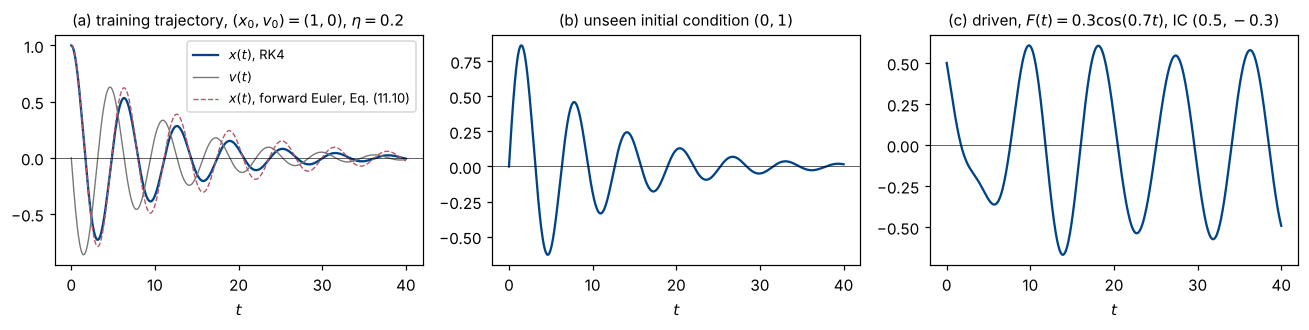

[Part 1] forward Euler against RK4 on the training trajectory: max |x_Euler - x_RK4| = 1.058e-01 at dt = 0.0501


In [3]:
ts, S_tr, S_ic, S_dr = fig_oscillator_data()

### 1b. The state-space form, the integrator, eigenmodes and transient growth (Sections 11.3.1 and 11.5.1)

Euler for *both* components gives $\boldsymbol{s}_{i+1} = \boldsymbol{A}\boldsymbol{s}_i + \boldsymbol{B}F_i$
with $\boldsymbol{A} = \begin{pmatrix}1 & \Delta t\\ -\Delta t & 1-\eta\Delta t\end{pmatrix}$,
$\boldsymbol{B} = (0, \Delta t)^T$, Eq. (11.15) — a linear recurrent network with
$\boldsymbol{W}=\boldsymbol{A}$, $\boldsymbol{U}=\boldsymbol{B}$, $\boldsymbol{V}=(1,0)$,
Eq. (11.17). The modulus of the eigenvalues of $\boldsymbol{A}$ decides whether a
perturbation grows or decays: for the undamped oscillator forward Euler has
$|1\pm i\Delta t| > 1$ and the amplitude grows by a factor $e$ over 800 steps,
which is why the training data are generated by RK4. The same numbers govern the
gradients later: $0.9^{100}$ and $1.1^{100}$, the derivative of $\tanh$ at $a=2$,
and the powers of the non-normal matrix of Eq. (11.43), whose eigenvalues are both
$0.9$ but whose norm first grows to $19$.

In [4]:
def state_space_matrices(dt=0.05, eta=ETA):
    """Eq. (11.15): the Euler step s_{i+1} = A s_i + B F_i for the damped
    oscillator (m = k = 1), its eigenvalues and their modulus."""
    A = np.array([[1.0, dt], [-dt, 1.0 - eta * dt]])
    B = np.array([0.0, dt])
    lam = np.linalg.eigvals(A)
    return A, B, lam


def euler_amplification(dt=0.05, T=40.0):
    """How much forward Euler amplifies the undamped and the damped oscillator
    over T time units, against the exact decay exp(-eta T / 2)."""
    n = int(round(T / dt))
    _, _, lam0 = state_space_matrices(dt, eta=0.0)
    _, _, lam = state_space_matrices(dt)
    mod0, mod = np.abs(lam0[0]), np.abs(lam[0])
    exact = np.exp(-ETA * dt / 2)
    return dict(n=n, mod_undamped=mod0, growth_undamped=mod0 ** n,
                mod_damped=mod, exact_per_step=exact, ratio=(mod / exact) ** n)


def eigenmode_numbers():
    """Section 11.5.2: the numbers behind the eigenmode argument."""
    return {"0.9**100": 0.9 ** 100, "1.1**100": 1.1 ** 100,
            "tanh'(2)": 1 - np.tanh(2.0) ** 2, "gain at w=2": 2 * (1 - np.tanh(2.0) ** 2)}


def transient_growth(W=np.array([[0.9, 5.0], [0.0, 0.9]]), kmax=40):
    """Eq. (11.43): a matrix with both eigenvalues 0.9 whose powers first grow.
    Returns k, ||W^k||_2 and the (1,2) entry of W^k."""
    ks, norms, entry = [], [], []
    P = np.eye(2)
    for k in range(1, kmax + 1):
        P = P @ W
        ks.append(k)
        norms.append(np.linalg.norm(P, 2))
        entry.append(P[0, 1])
    return np.array(ks), np.array(norms), np.array(entry)


A = [[ 1.    0.05]
 [-0.05  0.99]] 
B = [0.   0.05] 
eigenvalues [0.995+0.04974937j 0.995-0.04974937j]  modulus 0.9962429422585637
{'n': 800, 'mod_undamped': np.float64(1.0012492197250393), 'growth_undamped': np.float64(2.7148917443813816), 'mod_damped': np.float64(0.9962429422585636), 'exact_per_step': np.float64(0.9950124791926823), 'ratio': np.float64(2.6877204867855857)}
{'0.9**100': 2.6561398887587544e-05, '1.1**100': 13780.61233982238, "tanh'(2)": np.float64(0.07065082485316443), 'gain at w=2': np.float64(0.14130164970632886)}
||W^k|| peaks at k = 9 with 19.38 ; (1,2) entry of W^10 = 19.37


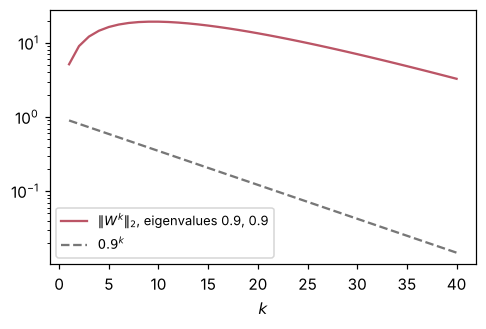

In [5]:
A, B, lam = state_space_matrices()
print("A =", A, "\nB =", B, "\neigenvalues", lam, " modulus", abs(lam[0]))
print(euler_amplification())
print(eigenmode_numbers())
ks, norms, entry = transient_growth()
print("||W^k|| peaks at k =", ks[norms.argmax()], "with", norms.max().round(2), "; (1,2) entry of W^10 =", entry[9].round(2))
fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(ks, norms, color=RED, label=r"$\|W^k\|_2$, eigenvalues 0.9, 0.9")
ax.semilogy(ks, 0.9 ** ks, "--", color=GREY, label=r"$0.9^k$")
ax.set_xlabel("$k$"); ax.legend(); plt.show()

## Part 2: the RNN as a discrete-time dynamical system (Section 11.2.1)

The simple RNN, Eq. (11.4), is

$$\boldsymbol{a}^{(t)} = \boldsymbol{U}\boldsymbol{x}^{(t)} + \boldsymbol{W}\boldsymbol{h}^{(t-1)} + \boldsymbol{b},\quad
\boldsymbol{h}^{(t)} = \sigma_h(\boldsymbol{a}^{(t)}),\quad
\boldsymbol{o}^{(t)} = \boldsymbol{V}\boldsymbol{h}^{(t)} + \boldsymbol{c},\quad
\hat{\boldsymbol{y}}^{(t)} = \sigma_y(\boldsymbol{o}^{(t)}),$$

with the *same* $\boldsymbol{U}, \boldsymbol{W}, \boldsymbol{V}$ at every
step (parameter sharing in time, the analogue of the parameter sharing in
space of a convolution) and the cost accumulated over the sequence,
Eq. (11.5). Set the input to zero and Eq. (11.4) becomes an autonomous map,
Eq. (11.6), $\boldsymbol{h}^{(t)} = F(\boldsymbol{h}^{(t-1)}) =
\sigma_h(\boldsymbol{W}\boldsymbol{h}^{(t-1)} + \boldsymbol{b})$, whose
fixed points are stable when the spectral radius of the Jacobian
$\boldsymbol{J} = \mathrm{diag}(\sigma_h'(\boldsymbol{a}^\star))\boldsymbol{W}$,
Eq. (11.7), is below one.

In one dimension, $h \mapsto \tanh(Wh)$: $0$ is always a fixed point, stable
for $|W|<1$; at $W=1$ a pitchfork bifurcation produces two stable non-zero
fixed points. A network with $|W|<1$ *forgets* its initial condition at the
rate $|W|^t$ — and in Part 4 the same number reappears as the size of the
gradient that travels $t$ steps backwards.

The twenty-dimensional network of panel (c) is a PyTorch `nn.RNN` whose
recurrent matrix `weight_hh_l0` has been rescaled to a prescribed spectral
radius (`scaled_rnn`, reused in Part 4) and which is driven by zero input
from a random initial state of norm one.

In [6]:
def tanh_map_iterates(W, h0=0.9, n=30):
    """Iterates of the one-dimensional autonomous map h -> tanh(W h), Eq. (11.6)."""
    h = np.zeros(n + 1)
    h[0] = h0
    for t in range(n):
        h[t + 1] = np.tanh(W * h[t])
    return h


def tanh_fixed_point(W, tol=1e-14):
    """The positive fixed point h* = tanh(W h*) for W > 1 (0 otherwise), by bisection."""
    if W <= 1.0:
        return 0.0
    lo, hi = 1e-12, 1.0
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if np.tanh(W * mid) - mid > 0:
            lo = mid
        else:
            hi = mid
        if hi - lo < tol:
            break
    return 0.5 * (lo + hi)


def scaled_rnn(rho, n_h=20, n_x=1, seed=3):
    """An untrained torch nn.RNN (tanh, one layer) whose recurrent matrix W has
    spectral radius rho; biases zero, input matrix U standard normal.
    Returns the layer and the spectral norm sigma_max(W)."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    rnn = nn.RNN(n_x, n_h, batch_first=True)
    with torch.no_grad():
        W = torch.randn(n_h, n_h, dtype=torch.float64)
        W *= rho / np.max(np.abs(np.linalg.eigvals(W.numpy())))
        rnn.weight_hh_l0.copy_(W.float())
        rnn.weight_ih_l0.copy_(torch.randn(n_h, n_x))
        rnn.bias_ih_l0.zero_()
        rnn.bias_hh_l0.zero_()
    return rnn, float(np.linalg.norm(W.numpy(), 2))


def autonomous_norms(rho, n_h=20, T=60, seed=3):
    """||h_t|| for an untrained nn.RNN driven by zero input, Eq. (11.6), starting
    from a random h_0 of norm one: W scaled to spectral radius rho."""
    import torch
    rnn, _ = scaled_rnn(rho, n_h, seed=seed)
    g = torch.Generator().manual_seed(seed)
    h0 = torch.randn(1, 1, n_h, generator=g)
    h0 = h0 / h0.norm()
    X = torch.zeros(1, T, 1)                    # (batch, time, features): no input
    with torch.no_grad():
        out, _ = rnn(X, h0)                     # out[0, t] is h_{t+1}
    return np.concatenate([[1.0], out[0].norm(dim=1).numpy()])


def fig_dynamics():
    hs = np.linspace(-1.5, 1.5, 400)
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
    for W, c in [(0.5, BLUE), (1.0, GREY), (1.5, RED)]:
        ax[0].plot(hs, np.tanh(W * hs), color=c, label=f"$W={W}$")
    ax[0].plot(hs, hs, "k--", lw=0.7, label="$h$")
    ax[0].set_xlabel("$h^{(t-1)}$")
    ax[0].set_ylabel("$h^{(t)}=\\tanh(Wh^{(t-1)})$")
    ax[0].set_title("(a) the one-dimensional map, Eq. (11.6)")
    ax[0].legend()
    for W, c in [(0.5, BLUE), (1.0, GREY), (1.5, RED)]:
        h = tanh_map_iterates(W)
        ax[1].plot(h, "o-", ms=3, color=c, label=f"$W={W}$")
        if W > 1:
            ax[1].axhline(tanh_fixed_point(W), color=c, lw=0.6, ls=":")
    ax[1].set_xlabel("step $t$")
    ax[1].set_ylabel("$h^{(t)}$ from $h^{(0)}=0.9$")
    ax[1].set_title("(b) iterates: forget ($W<1$) or remember ($W>1$)")
    ax[1].legend()
    for rho, c in [(0.5, BLUE), (0.9, GREEN), (1.1, YELLOW), (1.5, RED)]:
        ax[2].semilogy(autonomous_norms(rho), color=c, label=f"$\\rho(W)={rho}$")
    ax[2].set_xlabel("step $t$")
    ax[2].set_ylabel("$\\|h^{(t)}\\|$")
    ax[2].set_title("(c) nn.RNN, $n_h=20$, no input: forget, or settle on an attractor")
    ax[2].legend()
    fig.tight_layout()
    savefig(fig, "week45rnn_dynamics")
    plt.close(fig)
    print("[Part 2] fixed points of h = tanh(W h):",
          ", ".join(f"W={W}: h*=±{tanh_fixed_point(W):.4f}" for W in [1.0, 1.2, 1.5, 2.0]))
    for W in [0.5, 0.9, 1.5]:
        h = tanh_map_iterates(W)
        print(f"         W={W}: h after 10 steps {h[10]:+.4f}, after 30 steps {h[30]:+.4f}")
    for rho in [0.5, 0.9, 1.1, 1.5]:
        n = autonomous_norms(rho)
        print(f"         rho={rho}: ||h_0||={n[0]:.3f}  ||h_10||={n[10]:.3e}  ||h_60||={n[60]:.3e}")


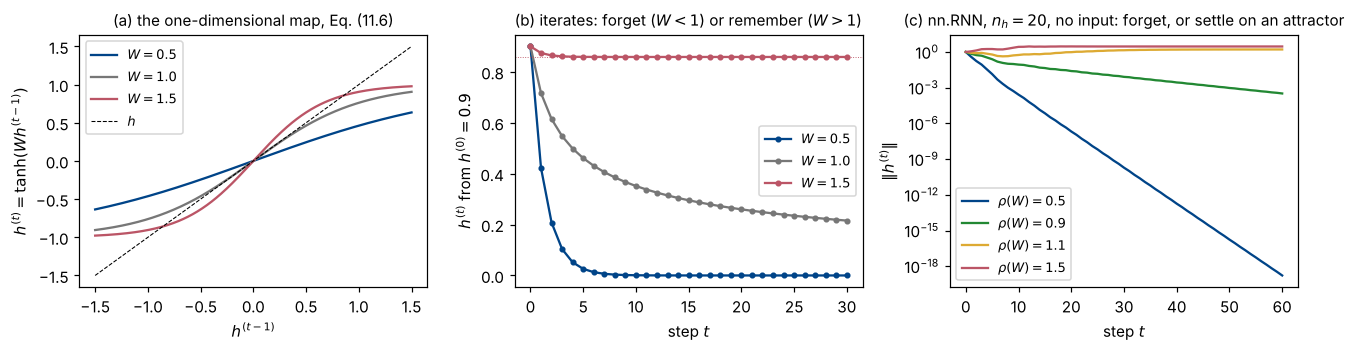

[Part 2] fixed points of h = tanh(W h): W=1.0: h*=±0.0000, W=1.2: h*=±0.6586, W=1.5: h*=±0.8586, W=2.0: h*=±0.9575
         W=0.5: h after 10 steps +0.0008, after 30 steps +0.0000
         W=0.9: h after 10 steps +0.1789, after 30 steps +0.0208
         W=1.5: h after 10 steps +0.8586, after 30 steps +0.8586
         rho=0.5: ||h_0||=1.000  ||h_10||=2.591e-04  ||h_60||=1.685e-19
         rho=0.9: ||h_0||=1.000  ||h_10||=8.671e-02  ||h_60||=3.261e-04
         rho=1.1: ||h_0||=1.000  ||h_10||=5.578e-01  ||h_60||=1.621e+00
         rho=1.5: ||h_0||=1.000  ||h_10||=2.687e+00  ||h_60||=2.888e+00


In [7]:
fig_dynamics()

## Part 3: the layers in Keras and PyTorch (Section 11.8)

Both libraries want a 3-tensor of shape `(samples, timesteps, features)`
$=(N, T, n_x)$; in PyTorch this needs `batch_first=True`. A Keras model for
one-step forecasting at every step of a window is

```python
model = keras.Sequential([keras.Input(shape=(None, 1)),               # (T, n_x), T may vary
                          layers.SimpleRNN(24, return_sequences=True), # Eq. (11.4): every h_t
                          layers.Dense(1)])                            # V h_t + c at every step
model.compile(optimizer=keras.optimizers.Adam(5e-3, clipnorm=1.0), loss="mse")
model.fit(X_train, Y_train, epochs=300, batch_size=4)
```

and the same in PyTorch separates the definition from the training loop:

```python
class Forecaster(nn.Module):
    def __init__(self, n_h=24):
        super().__init__()
        self.rnn = nn.RNN(1, n_h, batch_first=True)   # Eq. (11.4), tanh
        self.fc = nn.Linear(n_h, 1)                    # V h_t + c
    def forward(self, x):
        H, h_T = self.rnn(x)                           # H: (N, T, n_h), h_T: (1, N, n_h)
        return self.fc(H)

for epoch in range(300):
    for idx in torch.randperm(len(X_train)).split(4):
        opt.zero_grad(); loss = lossfn(model(X_train[idx]), Y_train[idx])
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
```

Three things worth checking before using either. The parameter counts:
Keras prints exactly $n_h(n_x+n_h+1)$ for `SimpleRNN` and four times that
for `LSTM`; PyTorch is larger by $n_h$ per gate because `nn.RNN` carries two
bias vectors (`bias_ih` and `bias_hh`) whose sum is our $\boldsymbol{b}$.
The conventions: Keras stores $\boldsymbol{U}$ and $\boldsymbol{W}$
transposed, and with the weights copied across the two layers agree to
single precision. And the backward pass: `loss.backward()` performs
backpropagation through time, Eqs. (11.19)–(11.22), which is a *fixed
linear map* of the output error — double the error and every gradient
doubles exactly (in float64).

In [8]:
def count_layer_parameters(n_x=1, n_h=24):
    """Parameter counts of the three recurrent cells in Keras and PyTorch
    against Eq. (11.4): n_h(n_x+n_h+1) for the simple RNN, four times that
    for the LSTM (four gates), three times for the GRU."""
    import torch.nn as nn
    from tensorflow import keras
    from tensorflow.keras import layers
    formula = n_h * (n_x + n_h + 1)
    print(f"[Part 3] parameters of one recurrent layer, n_x={n_x}, n_h={n_h}; "
          f"Eq. (11.4) gives n_h(n_x+n_h+1) = {formula}")
    print("           cell        Keras   PyTorch   formula   (PyTorch - Keras)/n_h")
    rows = []
    for name, K, P, k in [("simple RNN", layers.SimpleRNN, nn.RNN, 1),
                          ("LSTM", layers.LSTM, nn.LSTM, 4),
                          ("GRU", layers.GRU, nn.GRU, 3)]:
        m = keras.Sequential([keras.Input(shape=(None, n_x)), K(n_h)])
        nk = int(sum(np.prod(w.shape) for w in m.trainable_weights))
        np_ = sum(q.numel() for q in P(n_x, n_h).parameters())
        rows.append((name, nk, np_, k * formula))
        print(f"           {name:10s}  {nk:6d}  {np_:8d}  {k*formula:8d}   {(np_-nk)/n_h:.0f}")
    print("         PyTorch carries two bias vectors per gate (bias_ih and bias_hh), Keras one; "
          "the GRU in Keras uses reset_after=True, which also doubles its bias")
    return rows


def same_network_both_frameworks(n_x=2, n_h=5, T=7, seed=0):
    """Load one set of weights into nn.RNN and into SimpleRNN and compare the
    hidden states: U <-> kernel (transposed), W <-> recurrent_kernel
    (transposed), b <-> bias_ih + bias_hh.  Section 11.8.3."""
    import torch
    import torch.nn as nn
    from tensorflow import keras
    from tensorflow.keras import layers
    torch.manual_seed(seed)
    rnn = nn.RNN(n_x, n_h, batch_first=True)
    X = torch.randn(3, T, n_x)
    with torch.no_grad():
        H_torch, _ = rnn(X)                                   # (3, T, n_h): every h_t
    U = rnn.weight_ih_l0.detach().numpy()                     # (n_h, n_x)
    W = rnn.weight_hh_l0.detach().numpy()                     # (n_h, n_h)
    b = (rnn.bias_ih_l0 + rnn.bias_hh_l0).detach().numpy()    # one bias in Eq. (11.4)
    k = keras.Sequential([keras.Input(shape=(T, n_x)),
                          layers.SimpleRNN(n_h, return_sequences=True)])
    k.layers[0].set_weights([U.T, W.T, b])                    # Keras stores the transposes
    H_keras = k(X.numpy()).numpy()
    diff = np.max(np.abs(H_torch.numpy() - H_keras))
    print(f"[Part 3] the same U, W, b in nn.RNN and SimpleRNN, T={T}: "
          f"max |h_torch - h_keras| = {diff:.2e} (float32)")
    return diff


def backward_pass_is_linear(n_x=2, n_h=6, T=12, seed=0):
    """loss.backward() on nn.RNN: double the output error and every gradient
    doubles exactly -- the backward pass is a fixed linear map of the error
    (Section 11.4).  We use the cost 1/2 sum (yhat - y)^2 so that dL/dyhat is
    the error itself."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    rnn, fc = nn.RNN(n_x, n_h, batch_first=True).double(), nn.Linear(n_h, 1).double()
    params = list(rnn.parameters()) + list(fc.parameters())
    X = torch.randn(1, T, n_x, dtype=torch.float64)
    with torch.no_grad():
        y0 = fc(rnn(X)[0])                      # the network's own output
    target = y0 + torch.randn_like(y0)          # error e = yhat - target
    grads = []
    for scale in (1.0, 2.0):
        for q in params:
            q.grad = None
        yhat = fc(rnn(X)[0])
        loss = 0.5 * ((yhat - (y0 + scale * (target - y0))) ** 2).sum()
        loss.backward()                         # BPTT, Eqs. (11.20)-(11.22)
        grads.append([q.grad.clone() for q in params])
    err = max(float((2 * g1 - g2).abs().max() / g2.abs().max()) for g1, g2 in zip(*grads))
    print(f"[Part 3] loss.backward() is linear in the output error: "
          f"max |g(2e) - 2 g(e)| / max|g(2e)| = {err:.2e}")
    return err


def part3_numbers():
    count_layer_parameters()
    same_network_both_frameworks()
    backward_pass_is_linear()


In [9]:
part3_numbers()

[Part 3] parameters of one recurrent layer, n_x=1, n_h=24; Eq. (11.4) gives n_h(n_x+n_h+1) = 624
           cell        Keras   PyTorch   formula   (PyTorch - Keras)/n_h
           simple RNN     624       648       624   1
           LSTM          2496      2592      2496   4
           GRU           1944      1944      1872   0
         PyTorch carries two bias vectors per gate (bias_ih and bias_hh), Keras one; the GRU in Keras uses reset_after=True, which also doubles its bias


[Part 3] the same U, W, b in nn.RNN and SimpleRNN, T=7: max |h_torch - h_keras| = 1.19e-07 (float32)
[Part 3] loss.backward() is linear in the output error: max |g(2e) - 2 g(e)| / max|g(2e)| = 4.33e-16


### 3b. The worked example of Section 11.4.5 with `torch.autograd`

A scalar network $h_t = \tanh(u x_t + w h_{t-1})$, $o_t = v h_t$, one final target:
$u=v=1$, $w=0.5$, $h_0=0$, $(x_1,x_2)=(1,0)$, $y=0.5$. The hand calculation with the
boxed recursion (11.27) gives $\delta_2 = -0.118561$, $\delta_1 = -0.024896$ and
$\partial\mathcal{L}/\partial w = -0.090295$; autograd must agree to the last digit,
including the gradient with respect to the input $x_1$.

In [10]:
def two_step_by_hand_torch(u=1.0, v=1.0, w=0.5, h0=0.0, x=(1.0, 0.0), y=0.5):
    """The worked example of Section 11.4.5 -- a scalar RNN, two steps, one
    final target -- with the gradients from torch.autograd instead of by hand.
    h1 = tanh(u x1 + w h0), h2 = tanh(u x2 + w h1), L = (v h2 - y)^2 / 2."""
    import torch
    u_, v_, w_ = (torch.tensor(float(a), requires_grad=True) for a in (u, v, w))
    x1 = torch.tensor(x[0], requires_grad=True)
    x2 = torch.tensor(x[1])
    h1 = torch.tanh(u_ * x1 + w_ * h0)
    h2 = torch.tanh(u_ * x2 + w_ * h1)
    L = 0.5 * (v_ * h2 - y) ** 2
    L.backward()
    out = dict(h1=h1.item(), h2=h2.item(), e2=(v_ * h2 - y).item(), L=L.item(),
               dw=w_.grad.item(), du=u_.grad.item(), dv=v_.grad.item(), dx1=x1.grad.item())
    # by hand, Eq. (11.27): delta_2 = v e_2 (1 - h_2^2), delta_1 = w delta_2 (1 - h_1^2)
    d2 = v * out["e2"] * (1 - out["h2"] ** 2)
    d1 = w * d2 * (1 - out["h1"] ** 2)
    out.update(delta2=d2, delta1=d1, dw_hand=d2 * out["h1"] + d1 * h0, du_hand=d2 * x[1] + d1 * x[0],
               dv_hand=out["e2"] * out["h2"], dx1_hand=u * d1)
    # a centred finite difference in w, as the chapter does
    def Lw(wv):
        a1 = np.tanh(u * x[0] + wv * h0); a2 = np.tanh(u * x[1] + wv * a1)
        return 0.5 * (v * a2 - y) ** 2
    out["dw_fd"] = (Lw(w + 1e-5) - Lw(w - 1e-5)) / 2e-5
    return out


In [11]:
for k, v in two_step_by_hand_torch().items():
    print(f"{k:8s} {v: .6f}")

h1        0.761594
h2        0.363400
e2       -0.136600
L         0.009330
dw       -0.090295
du       -0.024896
dv       -0.049641
dx1      -0.024896
delta2   -0.118561
delta1   -0.024896
dw_hand  -0.090295
du_hand  -0.024896
dv_hand  -0.049641
dx1_hand -0.024896
dw_fd    -0.090295


## Part 4: why long sequences are hard (Sections 11.5 and 11.7.1)

Iterating Eq. (11.21) from $T$ back to $t$ produces a **product of
Jacobians**, Theorem 11.1, Eq. (11.38),

$$\frac{\partial\boldsymbol{h}^{(T)}}{\partial\boldsymbol{h}^{(t)}} = \prod_{k=t+1}^{T}\mathrm{diag}\!\left(\sigma_h'(\boldsymbol{a}^{(k)})\right)\boldsymbol{W},
\qquad
\left\|\frac{\partial\boldsymbol{h}^{(T)}}{\partial\boldsymbol{h}^{(t)}}\right\|_2 \le \left(\mu\,\sigma_{\max}(\boldsymbol{W})\right)^{T-t},$$

with $|\sigma_h'| \le \mu$ ($\mu = 1$ for $\tanh$, $1/4$ for the logistic
function — which is why $\tanh$ is the standard choice: a logistic recurrence
loses two bits of gradient per step whatever the weights). If
$\mu\sigma_{\max} < 1$ the contribution of step $t$ decays exponentially in
the lag, if $\mu\sigma_{\max} > 1$ it may grow exponentially. Corollary 11.2
names the decay scale, Eq. (11.40), $\tau = -1/\log(\mu\sigma_{\max})$ — the
**memory horizon**, the length of sequence the network can actually use.

We do not form the product by hand. `jacobian_product` builds an untrained
`nn.RNN` with $n_h = 20$, scales $\boldsymbol{W}$ to a prescribed spectral
radius, runs it for $T = 60$ steps on inputs small enough that
$\tanh' \approx 1$, and asks `torch.autograd.functional.jacobian` for
$\partial\boldsymbol{h}^{(T)}/\partial\boldsymbol{h}^{(t)}$ at every $t$ —
the function `h_T(h_t)` simply restarts the layer from $\boldsymbol{h}^{(t)}$
on the remaining inputs. `lstm_cell_path` does the same for an untrained
`nn.LSTM` whose forget-gate bias is set through `bias_ih_l0[n_h:2n_h]`
(PyTorch's gate order is $\boldsymbol{i},\boldsymbol{f},\boldsymbol{g},\boldsymbol{o}$),
and reports two numbers: the product of forget gates of Eq. (11.53), read
from the layer's own parameters, and the exact Jacobian
$\partial\boldsymbol{c}^{(T)}/\partial\boldsymbol{c}^{(t)}$ of
Proposition 11.4 from autograd.

In [12]:
def jacobian_product(rho, n_h=20, T=60, xscale=1e-3, seed=3):
    """||dh_T/dh_t||_2 for t = 1..T-1, Theorem 11.1, by torch.autograd on an
    untrained nn.RNN with W scaled to spectral radius rho and inputs small
    enough that tanh' ~ 1.  Returns the norms (index 0 is the lag T-1),
    sigma_max(W) and the mean over steps of max_i tanh'."""
    import torch
    rnn, smax = scaled_rnn(rho, n_h, seed=seed)
    g = torch.Generator().manual_seed(seed)
    X = torch.randn(1, T, 1, generator=g) * xscale
    with torch.no_grad():
        H, _ = rnn(X)                           # H[0, t-1] is h_t, t = 1..T
    norms = []
    for t in range(1, T):                       # lag T-t from T-1 down to 1
        def h_T(h_t):                           # run steps t+1..T from h_t
            out, _ = rnn(X[:, t:], h_t.view(1, 1, n_h))
            return out[0, -1]
        J = torch.autograd.functional.jacobian(h_T, H[0, t - 1])
        norms.append(float(torch.linalg.matrix_norm(J, 2)))
    dmax = float((1 - H[0] ** 2).max(dim=1).values.mean())
    return np.array(norms), smax, dmax


def fitted_horizon(norms):
    """Fit log||dh_T/dh_t|| = a - lag/tau over all lags (Corollary 11.2);
    returns tau (negative in the exploding regime)."""
    lags = np.arange(len(norms), 0, -1)        # norms[0] is lag T-1 ... norms[-1] lag 1
    slope = np.polyfit(lags, np.log(norms), 1)[0]
    return -1.0 / slope


def biased_lstm(forget_bias, n_h=20, n_x=1, seed=3):
    """An untrained nn.LSTM with Xavier-scaled weights, all biases zero except
    the forget gate, which starts at forget_bias (PyTorch gate order i,f,g,o)."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    lstm = nn.LSTM(n_x, n_h, batch_first=True)
    with torch.no_grad():
        lstm.weight_ih_l0.normal_(0, np.sqrt(1.0 / n_x))
        lstm.weight_hh_l0.normal_(0, np.sqrt(1.0 / n_h))
        lstm.bias_ih_l0.zero_()
        lstm.bias_hh_l0.zero_()
        lstm.bias_ih_l0[n_h:2 * n_h] = forget_bias          # the forget-gate slice
    return lstm


def lstm_cell_path(forget_bias, n_h=20, T=60, seed=3):
    """Two measurements on an untrained nn.LSTM for lags 1..T-1:
    the product of forget gates of Eq. (11.53), read from the layer's own
    parameters, and the exact Jacobian dc_T/dc_t of Proposition 11.4 from
    torch.autograd.  Returns (gate product norms, exact norms, mean f)."""
    import torch
    lstm = biased_lstm(forget_bias, n_h, seed=seed)
    g = torch.Generator().manual_seed(seed)
    X = torch.randn(1, T, 1, generator=g) * 1e-3
    Wf_x = lstm.weight_ih_l0[n_h:2 * n_h]
    Wf_h = lstm.weight_hh_l0[n_h:2 * n_h]
    bf = lstm.bias_ih_l0[n_h:2 * n_h] + lstm.bias_hh_l0[n_h:2 * n_h]
    h = torch.zeros(1, 1, n_h)
    c = torch.zeros(1, 1, n_h)
    F, C, Hs = [], [], []
    with torch.no_grad():
        for t in range(T):                      # one step at a time, to see c_t
            f = torch.sigmoid(X[:, t] @ Wf_x.T + h[0] @ Wf_h.T + bf)   # Eq. (11.49)
            _, (h, c) = lstm(X[:, t:t + 1], (h, c))
            F.append(f[0]); C.append(c.clone()); Hs.append(h.clone())
    prod = torch.ones(n_h)
    gate, exact = [], []
    for t in reversed(range(1, T)):            # lags 1 .. T-1
        prod = prod * F[t]                      # Eq. (11.53): product of forget gates
        gate.append(float(prod.norm()))

        def c_T(c_t):                           # exact dc_T/dc_t, Proposition 11.4
            _, (_, cT) = lstm(X[:, t:], (Hs[t - 1], c_t.view(1, 1, n_h)))
            return cT[0, 0]
        J = torch.autograd.functional.jacobian(c_T, C[t - 1][0, 0])
        exact.append(float(torch.linalg.matrix_norm(J, 2)))
    fmean = float(torch.stack(F).mean())
    return np.array(gate[::-1]), np.array(exact[::-1]), fmean


def fig_gradients(with_lstm=True):
    """Two panels for the week-45 lecture (simple RNN only); with_lstm=True
    adds the LSTM cell-path panel used in week 46."""
    T = 60
    lags = np.arange(T - 1, 0, -1)
    if with_lstm:
        fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
    else:
        fig, ax2 = plt.subplots(1, 2, figsize=(9, 3.4))
        ax = [ax2[0], None, ax2[1]]
    print("[Part 4] Theorem 11.1 measured with torch.autograd on nn.RNN (n_h=20, T=60, small inputs):")
    print("          rho(W)  sigma_max  mean max(tanh')   ||dh_T/dh_1||   bound sigma_max^59   fitted tau")
    rows = []
    for rho, c in [(0.5, BLUE), (0.9, GREEN), (1.1, YELLOW), (1.5, RED)]:
        n, s, d = jacobian_product(rho)
        tau = fitted_horizon(n)
        rows.append((rho, s, d, n[0], s ** 59, tau))
        print(f"          {rho:4.2f}  {s:8.3f}  {d:12.4f}   {n[0]:.3e}     {s**59:.3e}     {tau:8.2f}")
        ax[0].semilogy(lags, n, color=c, label=f"$\\rho(W)={rho}$, $\\sigma_{{\\max}}={s:.2f}$")
    ax[0].set_xlabel("lag $T-t$")
    ax[0].set_ylabel("$\\|\\partial h^{(T)}/\\partial h^{(t)}\\|_2$")
    ax[0].set_title("(a) nn.RNN: the Jacobian product, Eq. (11.38)")
    ax[0].legend(fontsize=7.5)
    if with_lstm:
        n05 = jacobian_product(0.5)[0]
        ax[1].semilogy(lags, n05, "--", color=GREY, label="simple RNN, $\\rho(W)=0.5$")
        print("         the LSTM cell path, untrained nn.LSTM, n_h=20, T=60:")
        print("           forget bias   mean f   gate product (11.53)   exact autograd (Prop. 11.4)")
        for fb, c in [(0.0, RED), (1.0, YELLOW), (2.0, BLUE)]:
            gate, exact, fm = lstm_cell_path(fb)
            print(f"           {fb:11.1f}   {fm:.4f}   {gate[0]:.3e}              {exact[0]:.3e}")
            ax[1].semilogy(lags, gate, color=c, label=f"gates only, $b_f={fb:.0f}$ (mean $f$={fm:.2f})")
            ax[1].semilogy(lags, exact, ":", color=c, lw=1.2, label=f"autograd, $b_f={fb:.0f}$")
        ax[1].set_xlabel("lag $T-t$")
        ax[1].set_ylabel("$\\|\\partial c^{(T)}/\\partial c^{(t)}\\|$")
        ax[1].set_title("(b) nn.LSTM: the constant error carousel, Eq. (11.53)")
        ax[1].legend(fontsize=6.5, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.28))
    rhos = np.linspace(0.3, 0.99, 24)
    taus, smax = [], []
    for r in rhos:
        n, s, _ = jacobian_product(r)
        taus.append(fitted_horizon(n))
        smax.append(s)
    taus, smax = np.array(taus), np.array(smax)
    bound = np.where(smax < 1, -1 / np.log(np.minimum(smax, 0.999999)), np.nan)
    ax[2].plot(rhos, taus, "o-", ms=3, color=BLUE, label="fitted $\\tau$ (steps)")
    ax[2].plot(rhos, bound, ":", color=RED, label="$-1/\\log\\sigma_{\\max}(W)$, Eq. (11.40), where $\\sigma_{\\max}<1$")
    ax[2].set_yscale("log")
    ax[2].set_xlabel("$\\rho(W)$")
    ax[2].set_ylabel("memory horizon $\\tau$")
    ax[2].set_title(("(c)" if with_lstm else "(b)") + " Corollary 11.2: how many steps the network remembers")
    ax[2].legend(fontsize=7.5)
    fig.tight_layout()
    savefig(fig, "week45rnn_gradients")
    plt.close(fig)
    print("         fitted memory horizon tau (steps) and the lag for a factor 1e-6:")
    for rho in [0.5, 0.7, 0.9, 0.95, 0.99]:
        n, s, _ = jacobian_product(rho)
        tau = fitted_horizon(n)
        print(f"           rho={rho:4.2f}  sigma_max={s:.3f}  tau={tau:6.2f}  lag(1e-6)={tau*np.log(1e6):6.1f}")
    print(f"         logistic instead of tanh: mu=1/4, so at least a factor 4^59 = {4.0**59:.1e} "
          f"lost over 59 steps whatever the weights")
    return rows


[Part 4] Theorem 11.1 measured with torch.autograd on nn.RNN (n_h=20, T=60, small inputs):
          rho(W)  sigma_max  mean max(tanh')   ||dh_T/dh_1||   bound sigma_max^59   fitted tau


          0.50     0.933        1.0000   2.878e-18     1.705e-02         1.44


          0.90     1.680        1.0000   3.313e-03     1.963e+13         9.38


          1.10     2.053        1.0000   4.547e+02     2.721e+18       -10.63


          1.50     2.800        0.9980   1.152e+02     2.410e+26       -20.40


         the LSTM cell path, untrained nn.LSTM, n_h=20, T=60:
           forget bias   mean f   gate product (11.53)   exact autograd (Prop. 11.4)


                   0.0   0.5000   7.759e-18              3.493e-07


                   1.0   0.7311   4.202e-08              1.269e+00


                   2.0   0.8803   2.435e-03              6.026e+03


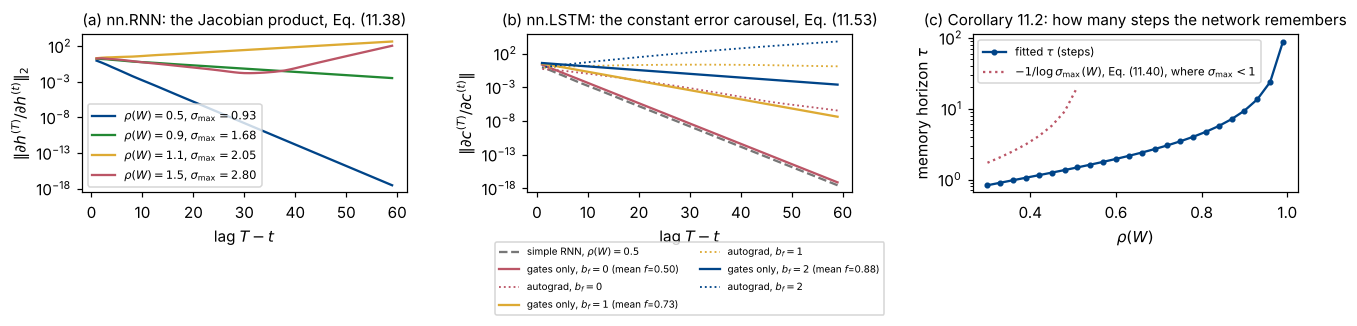

         fitted memory horizon tau (steps) and the lag for a factor 1e-6:


           rho=0.50  sigma_max=0.933  tau=  1.44  lag(1e-6)=  19.9


           rho=0.70  sigma_max=1.307  tau=  2.79  lag(1e-6)=  38.6


           rho=0.90  sigma_max=1.680  tau=  9.38  lag(1e-6)= 129.6


           rho=0.95  sigma_max=1.773  tau= 19.05  lag(1e-6)= 263.2


           rho=0.99  sigma_max=1.848  tau= 88.88  lag(1e-6)=1227.9
         logistic instead of tanh: mu=1/4, so at least a factor 4^59 = 3.3e+35 lost over 59 steps whatever the weights


In [13]:
rows = fig_gradients()

Three things to read off. At $\rho(\boldsymbol{W}) = 0.5$ the influence of
the first step on the last has fallen by eighteen orders of magnitude over
59 steps — the memory horizon is 1.4 steps. At $\rho = 1.1$ the same
quantity has grown to about $450$. And the LSTM with $b_f = 0$ transmits
$8\times10^{-18}$ along its cell path, *no better than the simple RNN it was
invented to replace*: the forget gates sit at $\sigma(0) = 1/2$ and the
product is $2^{-59}$. Biasing the gate open ($b_f = 1$, Keras's
`unit_forget_bias`) buys ten orders of magnitude along the cell path, and
the exact Jacobian — which includes the paths through the gates — is then
of order *one*: a gradient that survives sixty steps intact. At $b_f = 2$
the exact Jacobian is $6000$: nothing here prevents explosion, so clipping
stays. The architecture supplies a path; the initialisation decides whether
training starts anywhere near it. PyTorch's `nn.LSTM` does *not* bias the
forget gate by default; one line after construction does it.

Gradient clipping, Eq. (11.46), handles explosion cheaply: it is the
projection of the gradient onto a ball of radius $\theta$ (Proposition 11.3),
so it preserves the descent direction and bounds the step by $\gamma\theta$.
It does nothing for vanishing gradients — rescaling $10^{-18}$ upwards would
amplify rounding noise, not signal. In Keras it is `clipnorm=1.0` on the
optimiser; in PyTorch `nn.utils.clip_grad_norm_` between `backward()` and
`step()`.

## Part 5: the oscillator experiment, in Keras and in PyTorch (Section 11.6.1)

One trajectory, $\eta = 0.2$, $(x_0, v_0) = (1, 0)$, no forcing, 800 points;
the network sees only $x(t)$ and is trained to predict $x_{i+1}$ at every
step along 152 overlapping windows of length 40 (`make_windows`). The
same network in both libraries: `SimpleRNN(24, return_sequences=True)` /
`nn.RNN(1, 24)` followed by a read-out at every step, Adam at
$5\cdot10^{-3}$, clipping at $\theta = 1$, batches of 4 windows, 300 epochs.
The tests are trajectories the network never saw: a different initial
condition, $(0, 1)$, out of phase with everything in the training data, and
an oscillator driven by $F(t) = 0.3\cos(0.7t)$. The PyTorch loop records the
gradient norm that `clip_grad_norm_` returns before clipping.

Two remarks on sequential data. Training and test *windows* may be shuffled,
the points inside a window may not — shuffling in time decorrelates the
series and leaks the future into the past; and the split is by whole
trajectories, so every test trajectory has a new initial condition. The cost
is the mean squared error of Eq. (11.5): a forecasting problem is a regression
problem.

In [14]:
def make_windows(x, L=40, stride=5):
    """One-step-ahead forecasting as sequence-to-sequence: inputs x_i..x_{i+L-1},
    targets x_{i+1}..x_{i+L}; arrays of shape (windows, L, 1)."""
    idx = range(0, len(x) - L - 1, stride)
    X = np.stack([x[i:i + L] for i in idx])[..., None].astype("float32")
    Y = np.stack([x[i + 1:i + L + 1] for i in idx])[..., None].astype("float32")
    return X, Y


def oscillator_data(L=40, stride=5):
    """Windows from the training trajectory (1,0) and from the two test trajectories."""
    ts, S_tr, S_ic, S_dr = oscillator_trajectories()
    data = {name: make_windows(S[:, 0], L, stride) for name, S in
            [("train", S_tr), ("unseen IC", S_ic), ("driven", S_dr)]}
    var = {name: float(S[:, 0].var()) for name, S in
           [("train", S_tr), ("unseen IC", S_ic), ("driven", S_dr)]}
    return data, var


def keras_oscillator(n_h=24, epochs=300, lr=5e-3, theta=1.0, batch=4, seed=0):
    """SimpleRNN(n_h, return_sequences=True) + Dense(1): Eq. (11.4) with an
    output at every step; Adam with clipnorm=theta is Eq. (11.46)."""
    from tensorflow import keras
    from tensorflow.keras import layers
    keras.utils.set_random_seed(seed)
    data, var = oscillator_data()
    Xtr, Ytr = data["train"]
    model = keras.Sequential([keras.Input(shape=(None, 1)),            # any length
                              layers.SimpleRNN(n_h, return_sequences=True),
                              layers.Dense(1)])                         # read-out at every step
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=theta), loss="mse")
    n_par = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    t0 = time.time()
    hist = model.fit(Xtr, Ytr, epochs=epochs, batch_size=batch, verbose=0).history["loss"]
    res = {k: (float(model.evaluate(X, Y, verbose=0)), var[k]) for k, (X, Y) in data.items()}
    pred = {k: model.predict(data[k][0][::8][:12], verbose=0).ravel() for k in ("unseen IC", "driven")}
    true = {k: data[k][1][::8][:12].ravel() for k in ("unseen IC", "driven")}
    return dict(hist=np.array(hist), res=res, pred=pred, true=true, n_par=n_par,
                seconds=time.time() - t0, n_seq=len(Xtr))


def torch_oscillator(n_h=24, epochs=300, lr=5e-3, theta=1.0, batch=4, seed=0):
    """nn.RNN(1, n_h) + nn.Linear(n_h, 1) applied to every hidden state; the
    training loop records the gradient norm that clip_grad_norm_ sees."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    data, var = oscillator_data()
    Xtr, Ytr = map(torch.tensor, data["train"])

    class Forecaster(nn.Module):
        def __init__(self):
            super().__init__()
            self.rnn = nn.RNN(1, n_h, batch_first=True)   # Eq. (11.4), tanh
            self.fc = nn.Linear(n_h, 1)                    # V h_t + c at every t

        def forward(self, x):
            H, h_T = self.rnn(x)                           # H: (N, T, n_h), all h_t
            return self.fc(H)                              # (N, T, 1)

    model = Forecaster()
    n_par = sum(q.numel() for q in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossfn = nn.MSELoss()
    hist, gnorms, t0 = [], [], time.time()
    for ep in range(epochs):
        tot, nb = 0.0, 0
        for idx in torch.randperm(len(Xtr)).split(batch):  # windows shuffled, time inside kept
            opt.zero_grad(set_to_none=True)
            loss = lossfn(model(Xtr[idx]), Ytr[idx])
            loss.backward()                                            # BPTT
            gnorms.append(float(nn.utils.clip_grad_norm_(model.parameters(), theta)))  # Eq. (11.46)
            opt.step()
            tot += loss.item(); nb += 1
        hist.append(tot / nb)
    model.eval()
    with torch.no_grad():
        res = {k: (lossfn(model(torch.tensor(X)), torch.tensor(Y)).item(), var[k])
               for k, (X, Y) in data.items()}
        pred = {k: model(torch.tensor(data[k][0][::8][:12])).numpy().ravel()
                for k in ("unseen IC", "driven")}
    true = {k: data[k][1][::8][:12].ravel() for k in ("unseen IC", "driven")}
    return dict(hist=np.array(hist), res=res, pred=pred, true=true, n_par=n_par,
                gnorms=np.array(gnorms), theta=theta, seconds=time.time() - t0, n_seq=len(Xtr))


def fig_oscillator(K, P):
    fig, ax = plt.subplots(1, 4, figsize=(13.5, 3.1))
    ax[0].semilogy(np.arange(1, len(K["hist"]) + 1), K["hist"], color=BLUE, label="Keras SimpleRNN")
    ax[0].semilogy(np.arange(1, len(P["hist"]) + 1), P["hist"], color=RED, label="PyTorch nn.RNN")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("training mse, Eq. (11.5)")
    ax[0].set_title("(a) Adam, clipping at $\\theta=1$")
    ax[0].legend(fontsize=7.5)
    for a, key, title in [(ax[1], "unseen IC", "(b) unseen initial condition $(0,1)$"),
                          (ax[2], "driven", "(c) driven oscillator, never seen")]:
        a.plot(K["true"][key], color=GREY, lw=2.5, alpha=0.6, label="RK4")
        a.plot(K["pred"][key], color=BLUE, lw=0.9, label="Keras, one step ahead")
        a.plot(P["pred"][key], "--", color=RED, lw=0.9, label="PyTorch, one step ahead")
        a.set_title(title)
        a.set_xlabel("step (twelve test windows of length 40)")
        a.legend(fontsize=7.5)
    g = P["gnorms"]
    ax[3].hist(np.log10(g), bins=60, color=RED)
    ax[3].axvline(np.log10(P["theta"]), color=BLUE, ls="--", label=f"$\\theta={P['theta']}$")
    ax[3].set_xlabel("$\\log_{10}\\|\\nabla\\mathcal{L}\\|$ before clipping (PyTorch)")
    ax[3].set_title(f"(d) gradient norms: {int(np.sum(g > P['theta']))} of {len(g)} updates clipped")
    ax[3].legend(fontsize=7.5)
    fig.tight_layout()
    savefig(fig, "week45rnn_oscillator")
    plt.close(fig)
    print(f"[Part 5] {K['n_seq']} training windows of length 40 from ONE trajectory; n_h=24; "
          f"Keras {K['n_par']} parameters ({K['seconds']:.0f} s), PyTorch {P['n_par']} ({P['seconds']:.0f} s)")
    print("           set          Keras mse   PyTorch mse   Var(x)   relative (Keras / PyTorch)")
    for k in K["res"]:
        ek, v = K["res"][k]
        ep, _ = P["res"][k]
        print(f"           {k:10s}  {ek:.3e}    {ep:.3e}   {v:.4f}   {ek/v:.3%} / {ep/v:.3%}")
    print(f"         PyTorch gradient norms before clipping: median {np.median(g):.3f}, "
          f"max {g.max():.2f}, {int(np.sum(g > P['theta']))} of {len(g)} above theta={P['theta']}")


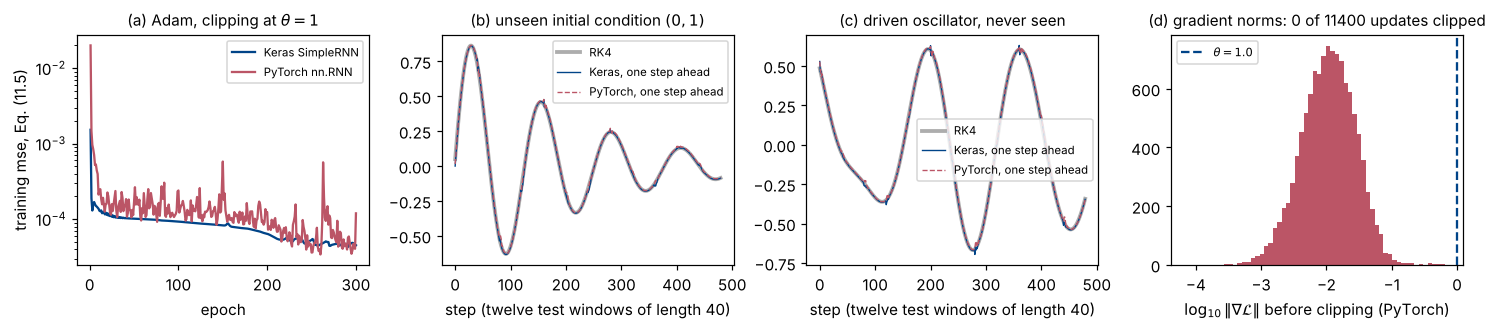

[Part 5] 152 training windows of length 40 from ONE trajectory; n_h=24; Keras 649 parameters (79 s), PyTorch 673 (31 s)
           set          Keras mse   PyTorch mse   Var(x)   relative (Keras / PyTorch)
           train       3.692e-05    1.056e-04   0.0655   0.056% / 0.161%
           unseen IC   3.811e-05    1.023e-04   0.0618   0.062% / 0.166%
           driven      4.970e-05    1.269e-04   0.1488   0.033% / 0.085%
         PyTorch gradient norms before clipping: median 0.011, max 0.77, 0 of 11400 above theta=1.0


In [15]:
K = keras_oscillator()
P = torch_oscillator()
fig_oscillator(K, P)

The second row of the table is the interesting one: trained on a trajectory
starting from rest at unit displacement, tested on one starting from the
origin at unit velocity, the error is *the same as the training error* in
both libraries; the driven oscillator is predicted just as well. The network
has not memorised a trajectory, it has learned the *update rule*, which is
what Eq. (11.12) said it would do — the same payoff parameter sharing gave in
week 44. The two libraries differ by a factor of three in the final error
(different initialisations and batch orders), both far below anything that
matters. With $\sigma_{\max}(\boldsymbol{W}) \approx 1$ at the start and
sequences of 40 steps, clipping never fired; it is insurance.

### 5b. One-step fit against free rollout (Section 11.6.2)

The forecaster above was trained — and tested — one step ahead, always fed the
*true* past. Closing the loop, Eq. (11.48), feeds its own predictions back:
errors are injected at every step and transported by the same Jacobian that
governed the gradients. We retrain the PyTorch forecaster (returning the model
this time), warm it up on 40 true steps of the unseen initial condition and
then let it run on its own output for 200 steps.

In [16]:
def torch_oscillator_model(n_h=24, epochs=300, lr=5e-3, theta=1.0, batch=4, seed=0):
    """The PyTorch forecaster of Part 5 again, but returning the trained model
    so that it can be rolled out freely (Section 11.6.2)."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    data, var = oscillator_data()
    Xtr, Ytr = map(torch.tensor, data["train"])

    class Forecaster(nn.Module):
        def __init__(self):
            super().__init__()
            self.rnn = nn.RNN(1, n_h, batch_first=True)
            self.fc = nn.Linear(n_h, 1)

        def forward(self, x, h=None):
            H, h = self.rnn(x, h)
            return self.fc(H), h

    model = Forecaster()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossfn = nn.MSELoss()
    for ep in range(epochs):
        for idx in torch.randperm(len(Xtr)).split(batch):
            opt.zero_grad(set_to_none=True)
            loss = lossfn(model(Xtr[idx])[0], Ytr[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), theta)
            opt.step()
    return model.eval()


def free_rollout(model, warmup=40, horizon=200):
    """Section 11.6.2: on the unseen initial condition (0, 1), feed the model
    the true x for `warmup` steps, then feed its own predictions back for
    `horizon` steps (free rollout), against the one-step-ahead predictions
    that always see the true past (teacher forcing).  Returns the true
    trajectory segment, both predictions and the two error curves."""
    import torch
    ts, S_tr, S_ic, S_dr = oscillator_trajectories()
    x = S_ic[:, 0].astype("float32")
    seg = x[: warmup + horizon + 1]
    with torch.no_grad():
        # teacher forcing: one step ahead at every position
        one_step = model(torch.tensor(seg[:-1])[None, :, None])[0].numpy().ravel()
        # free rollout: warm up on the truth, then close the loop
        _, h = model(torch.tensor(seg[:warmup])[None, :, None])
        xt = torch.tensor(seg[warmup - 1]).reshape(1, 1, 1)
        roll = []
        for _ in range(horizon):
            yhat, h = model(xt, h)
            roll.append(yhat.item())
            xt = yhat
    roll = np.array(roll)
    truth = seg[1:]
    err_one = np.abs(one_step[warmup - 1:] - truth[warmup - 1:])
    err_roll = np.abs(roll - truth[warmup - 1:warmup - 1 + horizon])
    return dict(truth=truth, one_step=one_step, roll=roll, warmup=warmup,
                err_one=err_one, err_roll=err_roll, ts=ts[1: warmup + horizon + 1])


def fig_rollout(R):
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
    w = R["warmup"]
    ax[0].plot(R["ts"], R["truth"], color=GREY, lw=2.5, alpha=0.6, label="RK4, unseen IC $(0,1)$")
    ax[0].plot(R["ts"], R["one_step"], color=BLUE, lw=0.9, label="one step ahead (sees the true past)")
    ax[0].plot(R["ts"][w - 1:w - 1 + len(R["roll"])], R["roll"], "--", color=RED, lw=1.1,
               label="free rollout (fed its own output)")
    ax[0].axvline(R["ts"][w - 1], color="k", lw=0.6, ls=":")
    ax[0].set_xlabel("$t$")
    ax[0].set_ylabel("$x(t)$")
    ax[0].set_title("(a) closing the loop after 40 true steps")
    ax[0].legend(fontsize=7)
    k = np.arange(1, len(R["err_roll"]) + 1)
    ax[1].semilogy(k, R["err_one"][:len(k)], color=BLUE, label="one-step error")
    ax[1].semilogy(k, R["err_roll"], color=RED, label="rollout error")
    ax[1].set_xlabel("steps after the loop is closed")
    ax[1].set_ylabel("$|\\hat x - x|$")
    ax[1].set_title("(b) Eq. (11.48): errors are fed back and compound")
    ax[1].legend(fontsize=7.5)
    fig.tight_layout()
    savefig(fig, "week45rnn_rollout")
    plt.close(fig)
    print(f"[rollout] one-step error: median {np.median(R['err_one']):.2e}, max {R['err_one'].max():.2e}; "
          f"rollout error after 10/50/100/200 steps: "
          + ", ".join(f"{R['err_roll'][i-1]:.2e}" for i in (10, 50, 100, 200)))


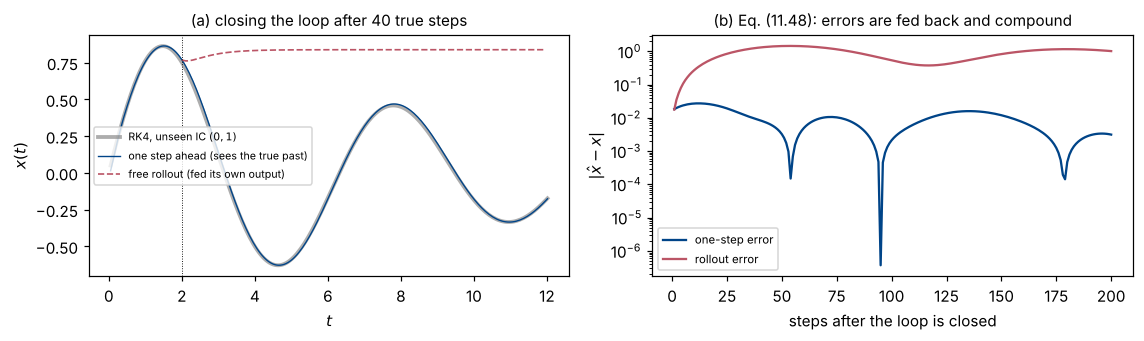

[rollout] one-step error: median 8.27e-03, max 2.75e-02; rollout error after 10/50/100/200 steps: 2.71e-01, 1.45e+00, 5.38e-01, 1.02e+00


In [17]:
R = free_rollout(torch_oscillator_model())
fig_rollout(R)

The one-step error stays at $10^{-2}$; the free rollout freezes at a constant
within twenty steps. At $\Delta t = 0.05$ a map close to the identity already has
a tiny one-step loss, and nothing in the training checked whether the network
carried the velocity in its state. The "learned rule" is a one-step rule; the
rollout is the test it was never given. The remedies are in the training —
predict increments, train on multi-step rollouts through the network's own
outputs, or supply the missing state — not in the cell.

## Part 6: four applications (Section 11.8)

(a) **A sine wave, one step ahead**: windows of 20 consecutive values
predict the next; `SimpleRNN(16)` with the default
`return_sequences=False` and `nn.RNN` with `out[:, -1, :]` both read the
last state only — the sequence-to-label case of Eq. (11.1). The split is in
*time*: the last 20 % of the wave is the test set.

In [18]:
def sine_windows(seq_length=20, n=500):
    """A sine wave cut into overlapping windows; the target is the next value."""
    data = np.sin(np.linspace(0, 100, n)).astype("float32")
    X = np.stack([data[i:i + seq_length] for i in range(len(data) - seq_length)])[..., None]
    y = data[seq_length:].reshape(-1, 1)
    return X, y


def torch_sine(epochs=200, hidden=16, seed=1, lr=1e-2):
    """nn.RNN on the sine wave, Section 11.8.1; returns history, test predictions, parameters."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    X, y = sine_windows()
    X, y = torch.tensor(X), torch.tensor(y)
    split = int(0.8 * len(X))

    class SineRNN(nn.Module):
        """nn.RNN implements Eq. (11.4) with tanh; we read out the last state only."""
        def __init__(self, hidden=16):
            super().__init__()
            self.rnn = nn.RNN(input_size=1, hidden_size=hidden, batch_first=True)
            self.fc = nn.Linear(hidden, 1)

        def forward(self, x):
            out, h_T = self.rnn(x)                 # out: (N, T, hidden)
            return self.fc(out[:, -1, :])          # sequence-to-label, Eq. (11.1)

    model = SineRNN(hidden)
    n_par = sum(q.numel() for q in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossfn = nn.MSELoss()
    hist = []
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(split)
        tot, nb = 0.0, 0
        for i in range(0, split, 32):
            idx = perm[i:i + 32]
            opt.zero_grad(set_to_none=True)
            loss = lossfn(model(X[idx]), y[idx])
            loss.backward()                                    # BPTT, Eqs. (11.20)-(11.22)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # Eq. (11.46)
            opt.step()
            tot += loss.item()
            nb += 1
        model.eval()
        with torch.no_grad():
            te = lossfn(model(X[split:]), y[split:]).item()
        hist.append((epoch, tot / nb, te))
    with torch.no_grad():
        pred = model(X[split:]).numpy().ravel()
    return np.array(hist), pred, y[split:].numpy().ravel(), n_par


def keras_sine(epochs=200, hidden=16, seed=1, lr=1e-2):
    """SimpleRNN on the sine wave: exactly Eq. (11.4), tanh by default."""
    from tensorflow import keras
    from tensorflow.keras import layers
    keras.utils.set_random_seed(seed)
    X, y = sine_windows()
    split = int(0.8 * len(X))
    model = keras.Sequential([keras.Input(shape=(X.shape[1], 1)),
                              layers.SimpleRNN(hidden), layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0), loss="mse")
    n_par = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    h = model.fit(X[:split], y[:split], epochs=epochs, batch_size=32, verbose=0,
                  validation_data=(X[split:], y[split:]))
    hist = np.column_stack([np.arange(1, epochs + 1), h.history["loss"], h.history["val_loss"]])
    return hist, model.predict(X[split:], verbose=0).ravel(), y[split:].ravel(), n_par


def fig_sine(ht, pt, yt, npt, hk, pk, yk, npk):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    ax[0].plot(yt, color=GREY, lw=3, alpha=0.5, label="true")
    ax[0].plot(pt, color=RED, lw=0.9, label=f"PyTorch nn.RNN ({npt} parameters)")
    ax[0].plot(pk, "--", color=BLUE, lw=0.9, label=f"Keras SimpleRNN ({npk} parameters)")
    ax[0].set_xlabel("held-out window")
    ax[0].set_title("(a) one-step forecasts on the last 20% of the sine wave")
    ax[0].legend(fontsize=7.5)
    ax[1].semilogy(ht[:, 0], ht[:, 2], color=RED, label="PyTorch test mse")
    ax[1].semilogy(hk[:, 0], hk[:, 2], color=BLUE, label="Keras test mse")
    ax[1].semilogy(ht[:, 0], ht[:, 1], ":", color=RED, lw=0.8, label="PyTorch train")
    ax[1].semilogy(hk[:, 0], hk[:, 1], ":", color=BLUE, lw=0.8, label="Keras train")
    ax[1].set_xlabel("epoch")
    ax[1].set_title("(b) mean squared error, Adam, batches of 32")
    ax[1].legend(fontsize=7.5)
    fig.tight_layout()
    savefig(fig, "week45rnn_sine")
    plt.close(fig)
    print(f"[Part 6a] sine wave, 200 epochs: PyTorch train mse {ht[-1,1]:.6f} test {ht[-1,2]:.6f} "
          f"({npt} parameters); Keras train {hk[-1,1]:.6f} test {hk[-1,2]:.6f} ({npk} parameters); "
          f"rms error {np.sqrt(ht[-1,2]):.4f} / {np.sqrt(hk[-1,2]):.4f} on a signal of amplitude 1")


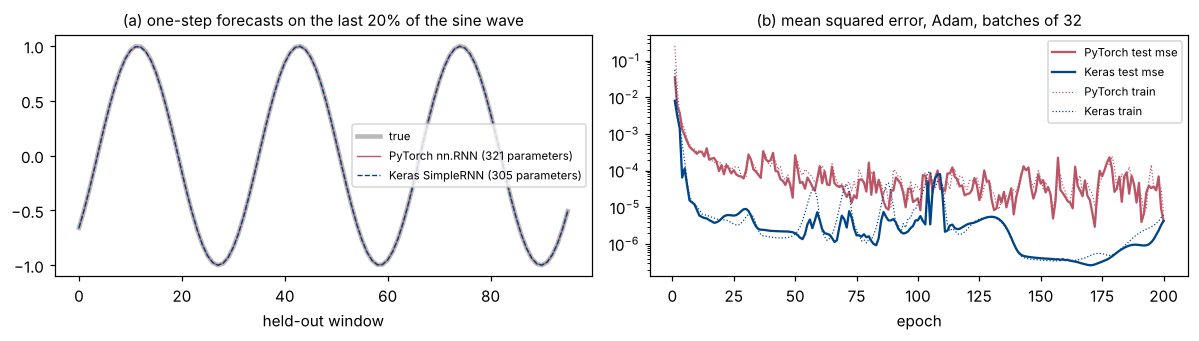

[Part 6a] sine wave, 200 epochs: PyTorch train mse 0.000008 test 0.000004 (321 parameters); Keras train 0.000006 test 0.000004 (305 parameters); rms error 0.0021 / 0.0021 on a signal of amplitude 1


In [19]:
ht, pt, yt, npt = torch_sine()
hk, pk, yk, npk = keras_sine()
fig_sine(ht, pt, yt, npt, hk, pk, yk, npk)

(b) **MNIST read row by row**: each $28\times28$ image as a sequence of 28
rows of 28 features, classified from the last state by an LSTM and, for
comparison, a simple RNN of the same width; three epochs, Adam $10^{-3}$,
batches of 64, the full 60 000 images from `mnist.npz`. Not what one does in
practice — week 44 explains why a CNN is the right tool — but a clean
sequence-to-label task. The parameter count $4n_h(n_x+n_h+1) = 80\,384$ for
the Keras LSTM is a check of the four gates.

In [20]:
def load_mnist_rows():
    """MNIST from the local mnist.npz as 28 rows of 28 features, scaled to [0,1]."""
    d = np.load(os.path.join(HERE, "mnist.npz"))
    xtr = d["x_train"].astype("float32") / 255.0
    xte = d["x_test"].astype("float32") / 255.0
    return (xtr, d["y_train"].astype("int64")), (xte, d["y_test"].astype("int64"))


def torch_mnist_rows(cell="lstm", epochs=3, hidden=128, seed=1):
    """MNIST read row by row with nn.LSTM or nn.RNN, Section 11.8.2."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    (xtr, ytr), (xte, yte) = load_mnist_rows()
    Xtr, Ytr, Xte, Yte = map(torch.tensor, (xtr, ytr, xte, yte))

    class RowNet(nn.Module):
        def __init__(self):
            super().__init__()
            C = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
            self.rnn = C(28, hidden, batch_first=True)   # 28 time steps of 28 features
            self.fc = nn.Linear(hidden, 10)

        def forward(self, x):
            return self.fc(self.rnn(x)[0][:, -1, :])     # last state -> class scores

    net = RowNet()
    n_par = sum(q.numel() for q in net.parameters())
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    lf = nn.CrossEntropyLoss()
    rows, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        net.train()
        perm = torch.randperm(len(Xtr))
        tot, nb = 0.0, 0
        for i in range(0, len(Xtr) - 64 + 1, 64):
            idx = perm[i:i + 64]
            opt.zero_grad(set_to_none=True)
            loss = lf(net(Xtr[idx]), Ytr[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            tot += loss.item()
            nb += 1
        net.eval()
        with torch.no_grad():
            pred = torch.cat([net(Xte[i:i + 1000]).argmax(1) for i in range(0, len(Xte), 1000)])
            acc = (pred == Yte).double().mean().item()
        rows.append((ep, tot / nb, acc, time.time() - t0))
    return np.array(rows), n_par


def keras_mnist_rows(cell="lstm", epochs=3, hidden=128, seed=1):
    """The same two networks in Keras."""
    from tensorflow import keras
    from tensorflow.keras import layers
    keras.utils.set_random_seed(seed)
    (xtr, ytr), (xte, yte) = load_mnist_rows()
    Layer = {"lstm": layers.LSTM, "rnn": layers.SimpleRNN, "gru": layers.GRU}[cell]
    m = keras.Sequential([keras.Input(shape=(28, 28)), Layer(hidden), layers.Dense(10)])
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
    n_par = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    rows, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        hh = m.fit(xtr, ytr, epochs=1, batch_size=64, verbose=0)
        _, acc = m.evaluate(xte, yte, verbose=0)
        rows.append((ep, hh.history["loss"][0], acc, time.time() - t0))
    return np.array(rows), n_par


def fig_mnist_rows(results):
    """results: dict (framework, cell) -> (rows, n_par)."""
    fig, ax = plt.subplots(1, 1, figsize=(6.2, 3.3))
    styles = {("PyTorch", "lstm"): (RED, "-"), ("PyTorch", "rnn"): (RED, "--"),
              ("TensorFlow", "lstm"): (BLUE, "-"), ("TensorFlow", "rnn"): (BLUE, "--")}
    print("[Part 6b] MNIST as 28 rows of 28, three epochs, Adam 1e-3, batches of 64, n_h=128:")
    print("           cell        framework    parameters  test accuracy  seconds")
    for (fw, cell), (rows, n_par) in results.items():
        c, ls = styles[(fw, cell)]
        ax.plot(rows[:, 0], 100 * rows[:, 2], ls, marker="o", ms=4, color=c,
                label=f"{fw} {'LSTM' if cell == 'lstm' else 'simple RNN'} ({n_par} par.)")
        print(f"           {cell:10s}  {fw:11s}  {n_par:10d}  {rows[-1,2]:13.4f}  {rows[-1,3]:7.0f}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("test accuracy (%)")
    ax.set_xticks([1, 2, 3])
    ax.set_title("MNIST read row by row" + (": LSTM against simple RNN" if any(c == "lstm" for _, c in results) else ": simple RNN"))
    ax.legend(fontsize=7.5)
    fig.tight_layout()
    savefig(fig, "week45rnn_mnist_rows")
    plt.close(fig)


[Part 6b] MNIST as 28 rows of 28, three epochs, Adam 1e-3, batches of 64, n_h=128:
           cell        framework    parameters  test accuracy  seconds
           lstm        PyTorch           82186         0.9708       30
           lstm        TensorFlow        81674         0.9735       57
           rnn         PyTorch           21514         0.9333       17
           rnn         TensorFlow        21386         0.9663       25


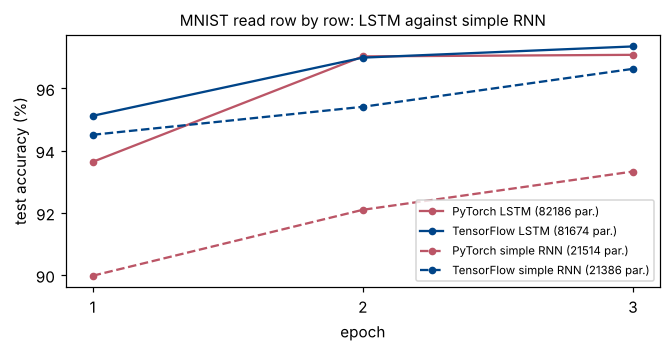

In [21]:
res = {}
for cell in ["lstm", "rnn"]:
    res[("PyTorch", cell)] = torch_mnist_rows(cell)
    res[("TensorFlow", cell)] = keras_mnist_rows(cell)
fig_mnist_rows(res)

The LSTM beats the simple RNN on a task with only 28 time steps — short
enough that the simple RNN works, just less well. Both reach about 0.97
where the convolutional network of week 44 reached 0.99 with a comparable
budget: reading an image as a sequence throws away the vertical structure
that a CNN was built to exploit.

(c) **Spoken digits.** The [Free Spoken Digit Dataset](https://github.com/Jakobovski/free-spoken-digit-dataset)
has 3000 recordings of the digits 0–9 by six speakers at 8 kHz, 0.15–2 s
each. A waveform of a few thousand samples is too long a sequence for a
recurrent layer and the information in speech sits in how the *spectrum*
changes with time, so we do what every speech system does: frames of 32 ms
every 16 ms, a Hann window, the power spectrum (the Fourier transform of a
windowed signal, Chapter 10), 129 bins averaged in pairs to 64 bands, the
logarithm, padded with silence or cut to 40 frames. The result is a
3-tensor `(3000, 40, 64)` — the data layout of Part 3 — and the models are
the MNIST ones with $28\to40$ steps and $28\to64$ features. The dataset's
standard split (recordings 0–4 of each digit and speaker are the test set)
is used first; then one *speaker* is held out instead. The features are
read from `fsdd_features.npz`; if that file is missing the wav files are
cloned from GitHub and the features computed and cached.

In [22]:
FSDD_URL = "https://github.com/Jakobovski/free-spoken-digit-dataset"
N_FRAMES, N_BINS = 40, 64              # 40 frames of 16 ms, 64 frequency bands


def read_wav(path):
    """A mono 16-bit wav file as floats in [-1, 1] and its sampling rate."""
    with wave.open(path) as w:
        rate = w.getframerate()
        x = np.frombuffer(w.readframes(w.getnframes()), dtype="<i2").astype("float32") / 32768.0
    return x, rate


def log_spectrogram(x, n_fft=256, hop=128, n_frames=N_FRAMES, n_bins=N_BINS):
    """Short-time log power spectrum: Hann-windowed frames of 32 ms every 16 ms
    (8 kHz), 129 frequency bins averaged in pairs to 64 bands, padded or cut
    to n_frames.  Shape (n_frames, n_bins): a sequence of n_frames vectors."""
    n_need = n_fft + hop * (n_frames - 1)
    x = np.pad(x, (0, max(0, n_need - len(x))))[:n_need]
    frames = np.stack([x[i * hop:i * hop + n_fft] for i in range(n_frames)])
    spec = np.abs(np.fft.rfft(frames * np.hanning(n_fft), axis=1)) ** 2   # (n_frames, 129)
    spec = spec[:, :2 * n_bins].reshape(n_frames, n_bins, 2).mean(axis=2)  # (n_frames, 64)
    return np.log10(spec + 1e-8).astype("float32")


def load_spoken_digits(cache="fsdd_features.npz"):
    """The Free Spoken Digit Dataset as log spectrograms.  Returns a dict with
    X (3000, 40, 64), y (3000,), speaker (3000,), index (3000,) and three
    example waveforms for the figure.  Cached after the first run."""
    path = os.path.join(HERE, cache)
    if os.path.exists(path):
        d = np.load(path, allow_pickle=True)
        return {k: d[k] for k in d.files}
    rec = os.path.join(HERE, "fsdd", "recordings")
    if not os.path.isdir(rec):
        print(f"[Part 6c] cloning {FSDD_URL} (27 MB of wav files) ...")
        subprocess.run(["git", "clone", "--depth", "1", FSDD_URL, os.path.join(HERE, "fsdd")], check=True)
    files = sorted(glob.glob(os.path.join(rec, "*.wav")))
    X, y, spk, idx, examples = [], [], [], [], {}
    for f in files:
        name = os.path.basename(f)[:-4]
        digit, speaker, k = name.split("_")
        x, rate = read_wav(f)
        X.append(log_spectrogram(x))
        y.append(int(digit)); spk.append(speaker); idx.append(int(k))
        if speaker == "jackson" and k == "0" and digit in ("0", "3", "7"):
            examples[digit] = x
    d = dict(X=np.array(X, dtype="float16"), y=np.array(y), speaker=np.array(spk),
             index=np.array(idx), rate=rate,
             ex0=examples["0"], ex3=examples["3"], ex7=examples["7"])
    np.savez_compressed(path, **d)
    return d


def spoken_digit_split(d, held_out_speaker=None):
    """The dataset's standard split (recordings 0-4 of each digit and speaker
    are the test set, 10%), or a speaker-independent split."""
    X = d["X"].astype("float32")
    X = (X - X.mean()) / X.std()                       # one global standardisation
    if held_out_speaker is None:
        test = d["index"] < 5
    else:
        test = d["speaker"] == held_out_speaker
    return (X[~test], d["y"][~test]), (X[test], d["y"][test])


def keras_spoken_digits(d, cell="lstm", hidden=64, epochs=20, seed=1, held_out_speaker=None):
    """LSTM(64) reading 40 spectral frames of 64 bands, Dense(10) on the last state."""
    from tensorflow import keras
    from tensorflow.keras import layers
    keras.utils.set_random_seed(seed)
    (Xtr, ytr), (Xte, yte) = spoken_digit_split(d, held_out_speaker)
    Layer = {"lstm": layers.LSTM, "rnn": layers.SimpleRNN, "gru": layers.GRU}[cell]
    m = keras.Sequential([keras.Input(shape=(N_FRAMES, N_BINS)), Layer(hidden), layers.Dense(10)])
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
    n_par = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    t0 = time.time()
    h = m.fit(Xtr, ytr, epochs=epochs, batch_size=32, verbose=0, validation_data=(Xte, yte))
    rows = np.column_stack([np.arange(1, epochs + 1), h.history["loss"], h.history["val_accuracy"]])
    return rows, n_par, time.time() - t0


def torch_spoken_digits(d, cell="lstm", hidden=64, epochs=20, seed=1, held_out_speaker=None,
                        forget_bias=None):
    """The same network in PyTorch.  forget_bias=1.0 sets the forget-gate bias
    of nn.LSTM to one at the start, as Keras does by default (unit_forget_bias)."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    (Xtr, ytr), (Xte, yte) = spoken_digit_split(d, held_out_speaker)
    Xtr, ytr, Xte, yte = map(torch.tensor, (Xtr, ytr, Xte, yte))
    C = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
    core, head = C(N_BINS, hidden, batch_first=True), nn.Linear(hidden, 10)
    if forget_bias is not None and cell == "lstm":
        with torch.no_grad():
            core.bias_ih_l0[hidden:2 * hidden] = forget_bias     # gate order i, f, g, o
    params = list(core.parameters()) + list(head.parameters())
    opt, lf = torch.optim.Adam(params, lr=1e-3), nn.CrossEntropyLoss()
    rows, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        tot, nb = 0.0, 0
        for idx in torch.randperm(len(Xtr)).split(32):
            opt.zero_grad(set_to_none=True)
            loss = lf(head(core(Xtr[idx])[0][:, -1, :]), ytr[idx])   # last state -> scores
            loss.backward()
            nn.utils.clip_grad_norm_(params, 1.0)
            opt.step()
            tot += loss.item(); nb += 1
        with torch.no_grad():
            acc = (head(core(Xte)[0][:, -1, :]).argmax(1) == yte).double().mean().item()
        rows.append((ep, tot / nb, acc))
    return np.array(rows), sum(q.numel() for q in params), time.time() - t0


def fig_spoken_digits(d, results, speaker_rows=None):
    """results: dict (framework, cell) -> (rows, n_par, seconds)."""
    fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.2))
    x, rate = d["ex7"], int(d["rate"])
    t = np.arange(len(x)) / rate
    ax[0].plot(t, x, color=BLUE, lw=0.6)
    ax[0].set_xlabel("time (s)")
    ax[0].set_ylabel("amplitude")
    ax[0].set_title(f"(a) 'seven' (speaker jackson), {len(x)} samples at {rate} Hz")
    S = log_spectrogram(x)
    im = ax[1].imshow(S.T, origin="lower", aspect="auto", cmap="magma",
                      extent=[0, N_FRAMES * 128 / rate, 0, rate / 2 / 1000])
    ax[1].set_xlabel("time (s)")
    ax[1].set_ylabel("frequency (kHz)")
    ax[1].set_title("(b) its log spectrogram: 40 steps of 64 features")
    fig.colorbar(im, ax=ax[1], fraction=0.046, pad=0.03)
    styles = {("Keras", "lstm"): (BLUE, "-", "Keras LSTM"),
              ("Keras", "rnn"): (BLUE, "--", "Keras simple RNN"),
              ("PyTorch", "lstm"): (RED, "-", "PyTorch LSTM"),
              ("PyTorch", "lstm, $b_f=1$"): (YELLOW, "-", "PyTorch LSTM, forget bias 1"),
              ("PyTorch", "gru"): (RED, ":", "PyTorch GRU"),
              ("PyTorch", "rnn"): (RED, "--", "PyTorch simple RNN")}
    print("[Part 6c] spoken digits (FSDD, 3000 recordings, 6 speakers), 40 frames x 64 bands, "
          "Adam 1e-3, batches of 32, n_h=64, 20 epochs:")
    print("           cell             framework   parameters   test accuracy   seconds   split")
    for (fw, cell), (rows, n_par, sec) in results.items():
        c, ls, lab = styles[(fw, cell)]
        ax[2].plot(rows[:, 0], 100 * rows[:, 2], ls, marker="o", ms=3, color=c, label=lab)
        print(f"           {cell:15s}  {fw:9s}   {n_par:9d}   {rows[-1,2]:13.4f}   {sec:7.0f}   standard")
    if speaker_rows is not None:
        rows, n_par, sec, who = speaker_rows
        ax[2].plot(rows[:, 0], 100 * rows[:, 2], "-", marker="s", ms=3, color=GREEN,
                   label=f"PyTorch LSTM ($b_f=1$), speaker '{who}' held out")
        print(f"           {'lstm':15s}  {'PyTorch':9s}   {n_par:9d}   {rows[-1,2]:13.4f}   {sec:7.0f}   "
              f"speaker '{who}' held out")
    ax[2].set_xlabel("epoch")
    ax[2].set_ylabel("test accuracy (%)")
    ax[2].set_title("(c) sequence-to-label: which digit was spoken?")
    ax[2].legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.28))
    fig.tight_layout()
    savefig(fig, "week45rnn_digits")
    plt.close(fig)


In [23]:
d = load_spoken_digits()
from IPython.display import Audio, display
for digit in ("0", "3", "7"):
    print(f"'{digit}', speaker jackson:")
    display(Audio(d["ex" + digit], rate=int(d["rate"])))

'0', speaker jackson:


'3', speaker jackson:


'7', speaker jackson:


[Part 6c] spoken digits (FSDD, 3000 recordings, 6 speakers), 40 frames x 64 bands, Adam 1e-3, batches of 32, n_h=64, 20 epochs:
           cell             framework   parameters   test accuracy   seconds   split
           lstm             Keras           33674          0.9567        23   standard
           lstm             PyTorch         33930          0.9533         9   standard
           lstm, $b_f=1$    PyTorch         33930          0.9700         9   standard
           gru              PyTorch         25610          0.9333        18   standard
           rnn              Keras            8906          0.4567        12   standard
           rnn              PyTorch          8970          0.1467         7   standard
           lstm             PyTorch         33930          0.5800         8   speaker 'theo' held out


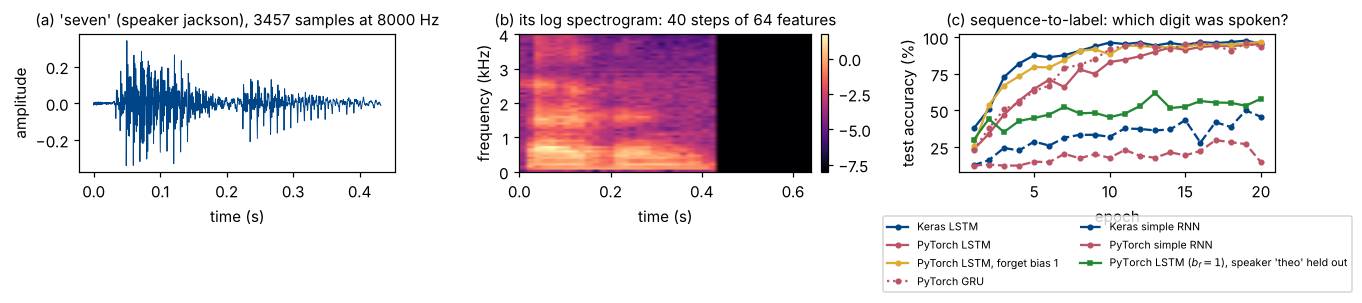

In [24]:
res = {("Keras", "lstm"): keras_spoken_digits(d),
       ("PyTorch", "lstm"): torch_spoken_digits(d),
       ("PyTorch", "lstm, $b_f=1$"): torch_spoken_digits(d, forget_bias=1.0),
       ("PyTorch", "gru"): torch_spoken_digits(d, cell="gru"),
       ("Keras", "rnn"): keras_spoken_digits(d, cell="rnn"),
       ("PyTorch", "rnn"): torch_spoken_digits(d, cell="rnn")}
sp = torch_spoken_digits(d, forget_bias=1.0, held_out_speaker="theo")
fig_spoken_digits(d, res, speaker_rows=(*sp, "theo"))

A gated cell classifies a spoken digit from its spectrogram with 95–97 %
accuracy after twenty epochs and half a minute of training; the GRU is close
behind with three quarters of the parameters. The simple RNN *fails* — 15 %
in PyTorch, 46 % in Keras, against a chance level of 10 %: forty steps is
beyond its memory horizon at initialisation, and the label depends on the
whole utterance. The two libraries' LSTMs agree to within half a point, and
setting the forget-gate bias to one in PyTorch adds almost two points on top
— the prediction of Part 4 on real data (the Keras numbers move by a point
or so between runs, since TensorFlow's threading is not seeded; the PyTorch
numbers are reproducible). And holding out one of the six speakers
instead of random recordings drops the accuracy to about 58 %: the standard
split tests whether the network recognises digits *from these speakers*, the
speaker split whether it recognises digits. The honest estimate for a system
meant to work on new voices is leave-one-speaker-out cross-validation.

(d) **The adding problem** (Section 11.8.5): two channels, uniform values
and two markers, one in each half of the sequence; the target is half the sum
of the two marked values. Nothing can be inferred from local statistics, so
the model must hold one number across the sequence while ignoring everything
in between. Predicting the mean and stopping gives a mean squared error of
about $0.043$. We compare `nn.RNN`, `nn.LSTM` and `nn.GRU` with $n_h = 32$ at
$T = 10, 30, 60, 120$, same seed, optimiser and epochs — the experiment that
decides whether the gates are worth their cost.

In [25]:
def adding_problem(n, T, rng):
    """Two channels: uniform values and two markers, one in each half; the
    target is half the sum of the two marked values (Section 11.8.5)."""
    v = rng.uniform(0, 1, (n, T)).astype("float32")
    m = np.zeros((n, T), dtype="float32")
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    m[np.arange(n), i1] = 1.0
    m[np.arange(n), i2] = 1.0
    y = (v[np.arange(n), i1] + v[np.arange(n), i2]).reshape(-1, 1) / 2.0
    return np.stack([v, m], -1), y


def torch_adding(lags=(10, 30, 60, 120), cells=("rnn", "lstm", "gru"), seeds=(0,),
                 epochs=40, hidden=32, verbose=True):
    """The adding problem at increasing sequence length; returns table (cells x lags) and baseline."""
    import torch
    import torch.nn as nn
    table = np.zeros((len(cells), len(lags)))
    base_row = np.zeros(len(lags))
    if verbose:
        print("[Part 6d] the adding problem, held-out mse (predicting the mean gives the baseline):")
        print("            T   baseline" + "".join(f"{c:>10s}" for c in cells))
    for j, T in enumerate(lags):
        Xr, yr = adding_problem(3000, T, np.random.default_rng(3))
        Xv, yv = adding_problem(1000, T, np.random.default_rng(4))
        Xr, yr, Xv, yv = map(torch.tensor, (Xr, yr, Xv, yv))
        base_row[j] = float(((yv - yv.mean()) ** 2).mean())
        line = f"          {T:4d} {base_row[j]:9.4f}"
        for i, cell in enumerate(cells):
            runs = []
            for sd in seeds:
                torch.manual_seed(sd)
                C = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
                core, head = C(2, hidden, batch_first=True), nn.Linear(hidden, 1)
                params = list(core.parameters()) + list(head.parameters())
                opt = torch.optim.Adam(params, lr=5e-3)
                lf = nn.MSELoss()
                for ep in range(epochs):
                    perm = torch.randperm(len(Xr))
                    for k in range(0, len(Xr), 64):
                        idx = perm[k:k + 64]
                        opt.zero_grad(set_to_none=True)
                        loss = lf(head(core(Xr[idx])[0][:, -1, :]), yr[idx])
                        loss.backward()
                        nn.utils.clip_grad_norm_(params, 1.0)
                        opt.step()
                with torch.no_grad():
                    runs.append(lf(head(core(Xv)[0][:, -1, :]), yv).item())
            table[i, j] = np.mean(runs)
            line += f"{table[i, j]:10.4f}"
        if verbose:
            print(line)
    return np.array(lags), table, base_row


def fig_adding(lags, table, base, cells=("rnn", "lstm", "gru")):
    fig, ax = plt.subplots(figsize=(6.2, 3.3))
    ax.set_ylim(5e-6, 0.1)
    for i, (cell, c) in enumerate(zip(cells, [RED, BLUE, GREEN])):
        ax.semilogy(lags, np.maximum(table[i], 1e-5), "o-", color=c,
                    label={"rnn": "simple RNN", "lstm": "LSTM", "gru": "GRU"}[cell])
    ax.semilogy(lags, base, ":", color=GREY, label="predict the mean")
    ax.set_xlabel("sequence length $T$")
    ax.set_ylabel("held-out mean squared error")
    ax.set_title("The adding problem: where the memory horizon runs out")
    ax.legend(fontsize=8)
    fig.tight_layout()
    savefig(fig, "week45rnn_adding")
    plt.close(fig)


[Part 6d] the adding problem, held-out mse (predicting the mean gives the baseline):
            T   baseline       rnn      lstm       gru


            10    0.0427    0.0013    0.0000    0.0000


            30    0.0429    0.0410    0.0001    0.0000


            60    0.0411    0.0405    0.0002    0.0001


           120    0.0425    0.0426    0.0003    0.0000


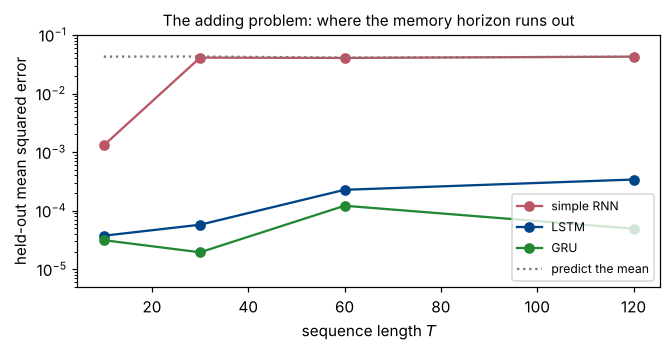

In [26]:
lags, table, base = torch_adding()
fig_adding(lags, table, base)

At $T = 10$ the simple recurrent network solves the task. At $T = 30$ it has
already failed completely — an error equal to the baseline is the error of a
model that outputs the mean and nothing else — and it never recovers at 60 or
120. The LSTM and the GRU solve every case, including $T = 120$, at errors two
to three orders of magnitude below the simple RNN with the same hidden width,
optimiser and epochs. Corollary 11.2 predicted this: a simple RNN initialised
in the usual way has a horizon of a few steps, so a dependency at lag 30 is
invisible to it; the gated cells replace the product of Jacobians by a product
of gates that training can drive towards one. The gap between $T = 10$ and
$T = 30$ is where the horizon runs out.

## Summary

A recurrent network is the architecture obtained by insisting that a model
respect the ordering of its data and reuse its parameters along the time
axis; the state-space form (11.3) makes it a learned dynamical system, and
the oscillator showed that the recurrence is exactly the structure of an
explicit time-stepping scheme. In the libraries it is one layer fed a
`(samples, timesteps, features)` tensor, and `loss.backward()` or
`model.fit` perform backpropagation through time exactly: a linear backward
pass whose gradient across a lag is a product of Jacobians — $10^{-18}$ over
59 steps at $\rho(\boldsymbol{W}) = 0.5$, measured with autograd. Clipping
handles explosion for free and does nothing for vanishing. The LSTM gives the
gradient an additive path whose Jacobian is a product of forget gates: of
order one over sixty steps when the gate starts open, $10^{-18}$ when it does
not. A simple RNN failed on forty-step spoken digits and on the adding
problem from $T = 30$; the LSTM and the GRU solved both. And a simple RNN
trained on one damped oscillation predicted an unseen initial condition and
an unseen forcing at the training error — one step ahead; fed its own
output it froze within twenty steps. A one-step loss certifies a one-step
rule, and the free rollout is the test that has to come with it.

**Reading:** Chapter 11 (all sections); Goodfellow et al. Chapter 10;
Raschka et al. Chapter 15; Pascanu, Mikolov and Bengio (ICML 2013).